# Predicción de rotación de personal (IBM HR Analytics)

Modelo de clasificación binaria con scikit-learn para estimar qué empleados tienen mayor riesgo de dejar la empresa. El énfasis está en la evaluación honesta: comparación contra un baseline, validación cruzada sin fuga de datos, análisis del umbral de decisión y una auditoría de las variables sensibles (edad, género y estado civil).

**Resultados clave**

- Regresión logística con ElasticNet: exactitud de 0.889 en validación cruzada frente a 0.839 del baseline (predecir siempre "No").
- En Test (221 empleados, 36 que se fueron) la exactitud es 0.860 contra 0.837 del baseline: una ventaja de 2.3 puntos que no es estadísticamente distinguible. Con el umbral por defecto el modelo detecta 14 de 36 salidas (recall 0.39).
- Bajar el umbral sube el recall a 0.64, pero obliga a marcar a un tercio de la plantilla con cerca de 70% de falsas alarmas: es un intercambio, no una mejora gratuita.
- Quitar edad, género y estado civil cuesta 0.01 de ROC-AUC o menos, así que no hay razón de desempeño para usarlas. Aun sin ellas, el recall difiere entre grupos de edad y de estado civil.

**Stack:** Python, pandas, scikit-learn, seaborn, matplotlib.

## 1. Problema y contexto de negocio

La rotación de personal es la salida de trabajadores de una organización y se mide como la proporción de empleados que se van en un periodo respecto a la plantilla. Es costosa: implica reclutar y seleccionar un reemplazo, capacitarlo, perder productividad durante la transición y, muchas veces, perder conocimiento acumulado.

El objetivo es estimar qué empleados tienen mayor riesgo de irse para que Recursos Humanos pueda abrir una conversación de retención a tiempo. El rasgo clave del problema es la asimetría de costos: **no detectar a alguien que se va (falso negativo) suele costar más que una falsa alarma (falso positivo)**, así que el recall de la clase "se va" importa más que la exactitud global.

**Datos:** [IBM HR Analytics Employee Attrition](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) (Kaggle), 1,470 empleados y 35 variables. Es un conjunto sintético generado por IBM que se usa ampliamente como referencia para este problema.

In [1]:
# Librerías

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report


## 2. Carga de datos

In [2]:
import os
archivo = 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

if os.path.exists(archivo):          # si ya tienes el CSV junto al notebook
    path = archivo
else:                                # si no, se descarga de Kaggle
    import kagglehub
    path = kagglehub.dataset_download('pavansubhasht/ibm-hr-analytics-attrition-dataset', path=archivo)

print(path)


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
/kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv


In [3]:
data = pd.read_csv(path)

print("Tamaño del DataFrame:", data.shape)
data.describe(include = 'all').T


Tamaño del DataFrame: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


## 3. Exploración inicial y limpieza

Se revisan tipos, distribuciones y categorías del conjunto completo (sin usar todavía la variable objetivo) para eliminar variables sin valor predictivo.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

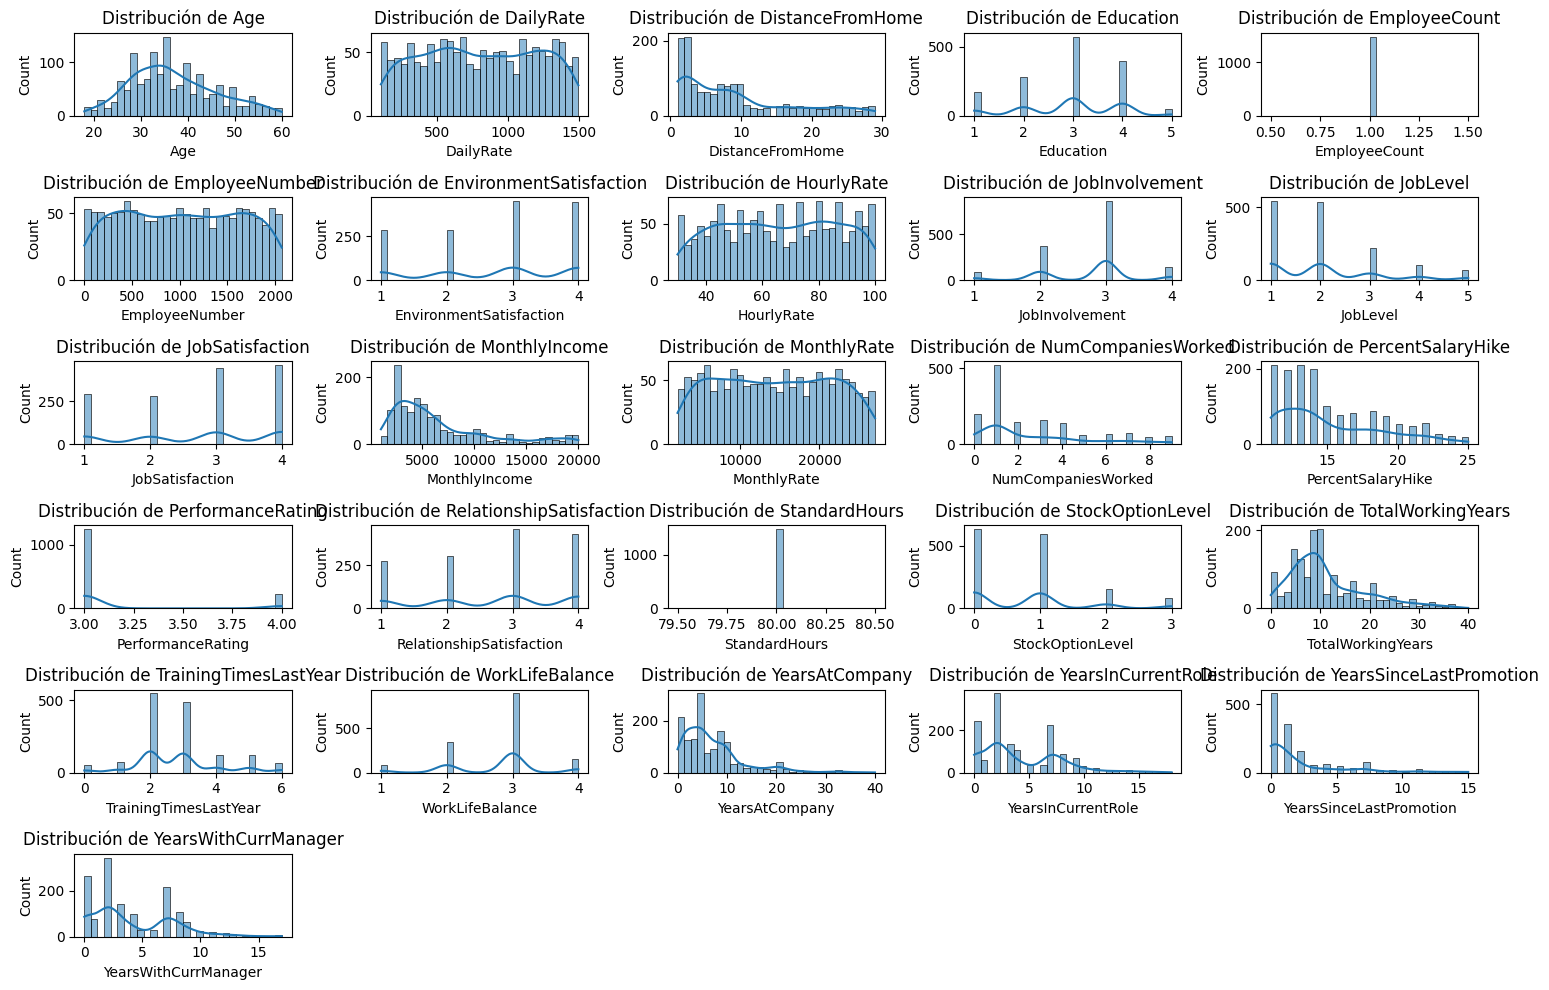

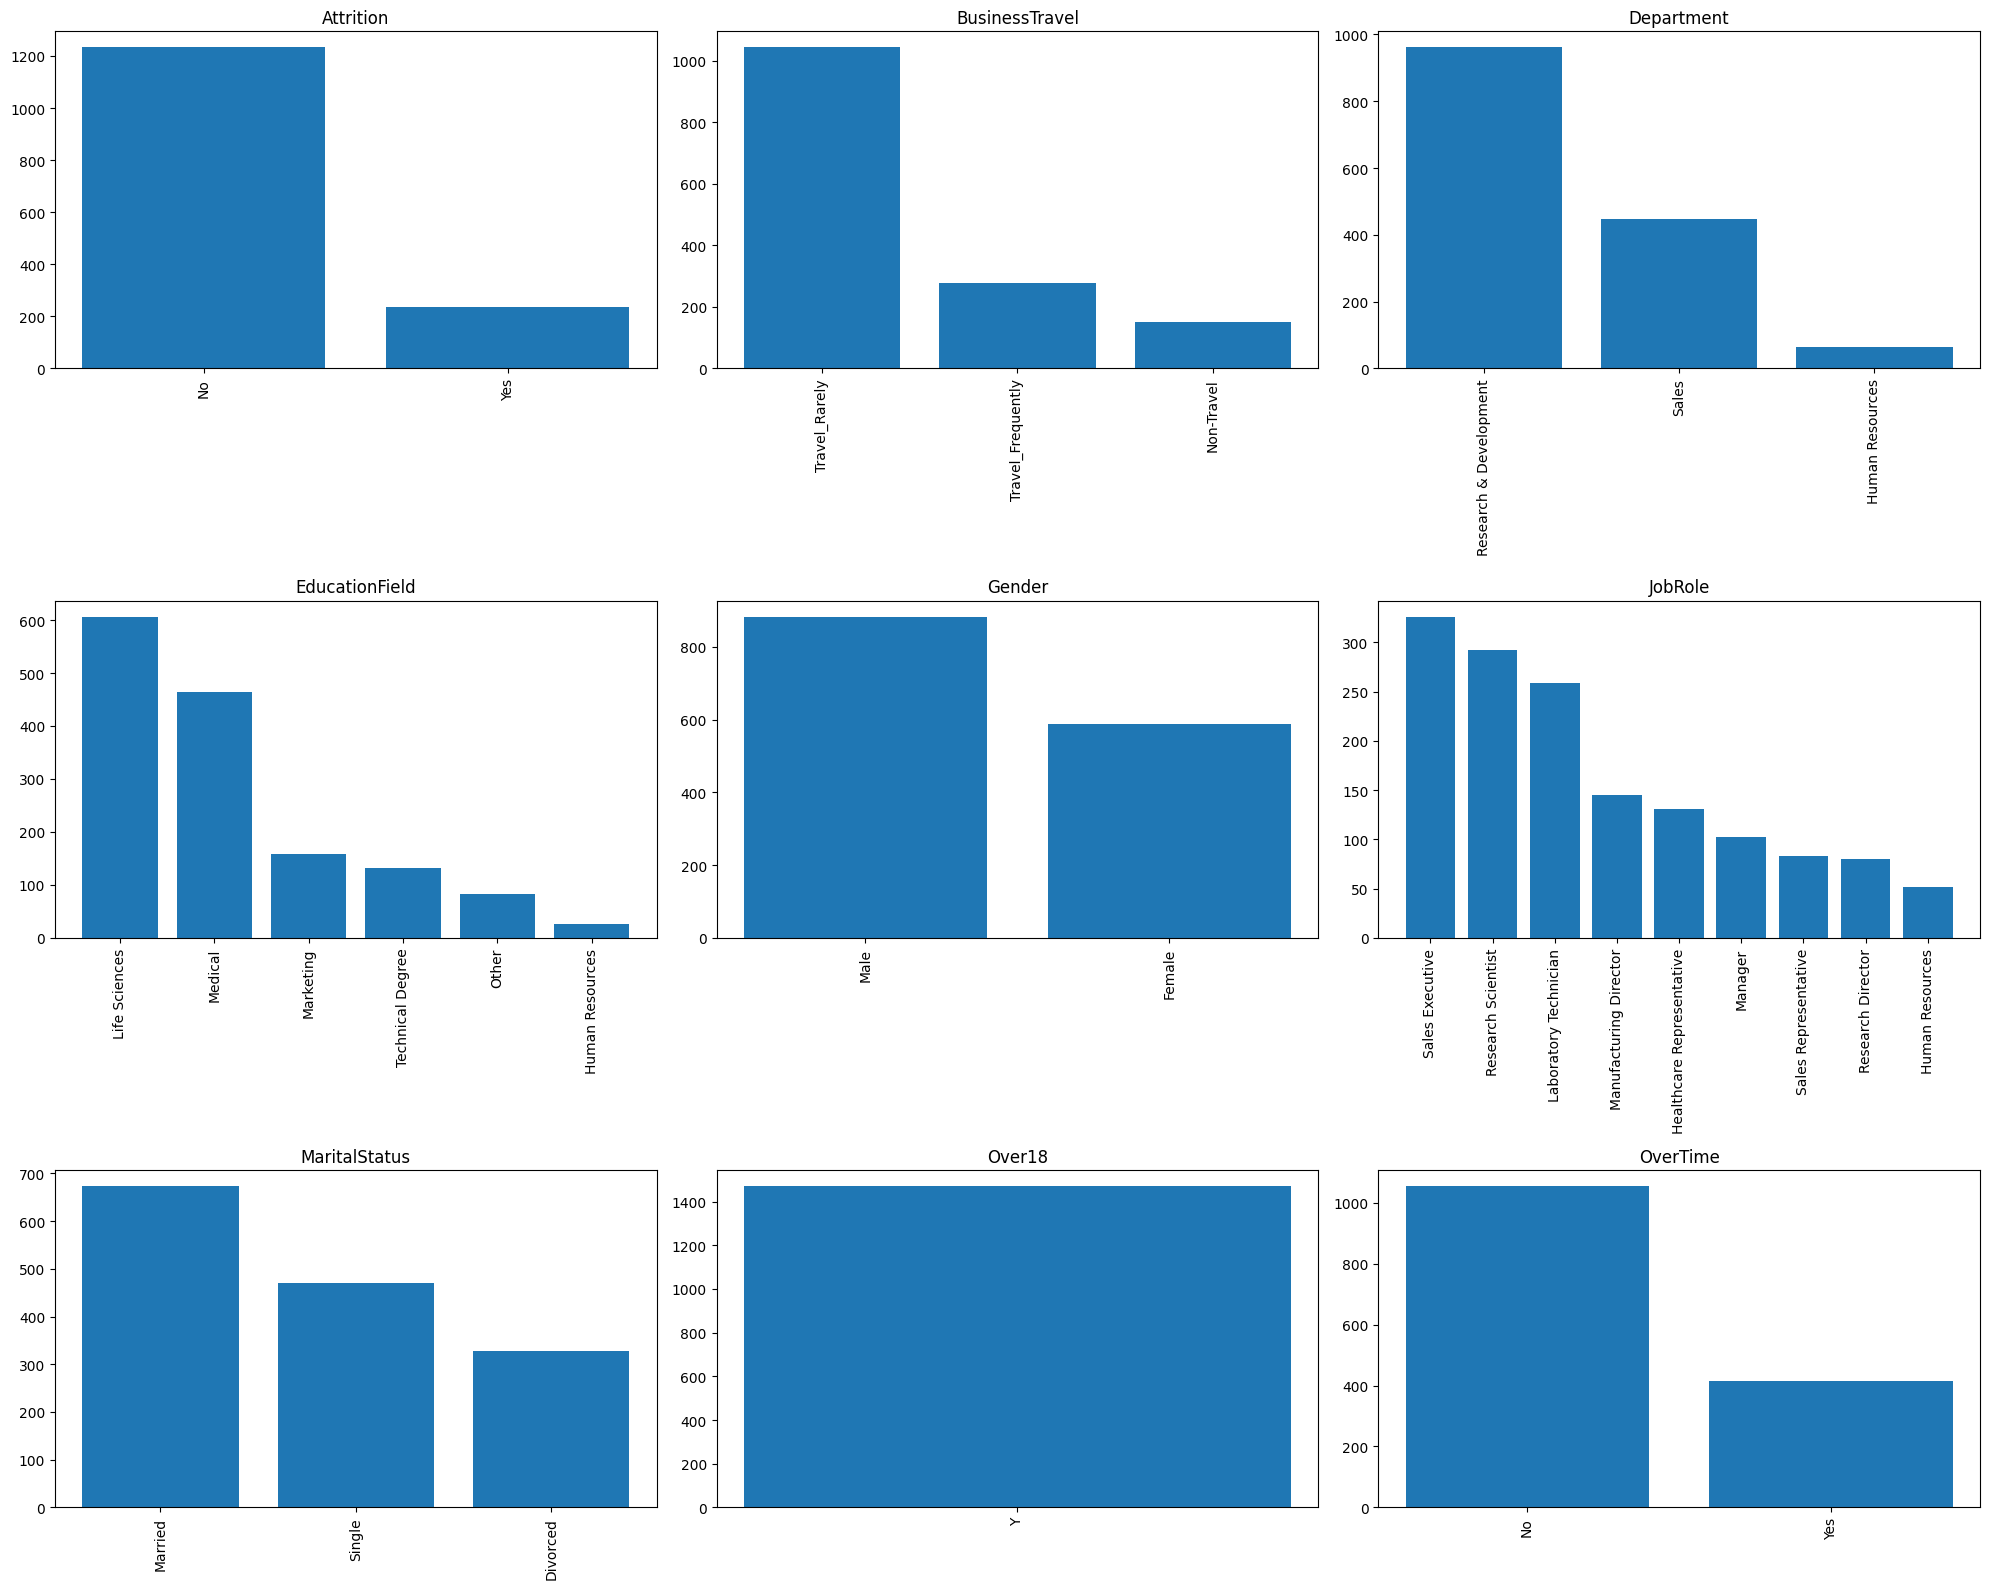

Tamaño del nuevo DataFrame: (1470, 31)


In [4]:
# Verificamos que tipo son nuestras variables
print(data.info())

# Separamos en categóricas y numéricas para un mejor análisis
cat_cols = data.select_dtypes(include=['object'])
num_cols = data.select_dtypes(include=['int64', 'float64'])

# Histogramas de variables numéricas
fig, axes = plt.subplots(6, 5, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.histplot(data=data, x=col, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribución de {col}')

# Ocultar ejes vacíos si num_cols.columns < 9
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

print('='*100)

# Gráficas de barras para las variables categóricas
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(cat_cols.columns):
    top10 = data[col].value_counts().head(10)
    axes[i].bar(top10.index, top10.values)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=90)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

print('='*100)
# Una vez explorado el dataset completo, eliminamos las variables sin valor predictivo
df = data.drop(columns=['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'])


# Verifiquemos de qué tamaño queda el nuevo DataFrame:
print("Tamaño del nuevo DataFrame:", df.shape)


Se eliminan 4 variables:

- `EmployeeCount`, `StandardHours` y `Over18` son constantes (1, 80 y "Y" en todos los registros): no tienen variabilidad y no pueden explicar la rotación.
- `EmployeeNumber` es un identificador único, sin relación con la decisión de irse.

Quedan 30 variables de entrada más `Attrition` (variable objetivo).

## 4. Tipos de variable y consideraciones éticas

| Tipo | Variables |
|---|---|
| Numéricas (14) | NumCompaniesWorked, TrainingTimesLastYear, Age, DailyRate, DistanceFromHome, HourlyRate, MonthlyIncome, MonthlyRate, PercentSalaryHike, TotalWorkingYears, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager |
| Ordinales (9) | Education (5), EnvironmentSatisfaction (4), JobInvolvement (4), JobLevel (5), JobSatisfaction (4), PerformanceRating (2), RelationshipSatisfaction (4), StockOptionLevel (4), WorkLifeBalance (4) |
| Binarias (3) | Attrition (objetivo), Gender, OverTime |
| Nominales (5) | BusinessTravel (3), Department (3), EducationField (6), JobRole (9), MaritalStatus (3) |

**Variables sensibles.** Age, Gender y MaritalStatus son categorías protegidas en la mayoría de los marcos laborales. Un modelo que las use puede reproducir sesgos históricos y exponer a la empresa a riesgo legal aunque la decisión sea algorítmica. Eliminarlas no basta, porque otras variables pueden actuar como proxy (por ejemplo, los años de experiencia respecto a la edad). Por eso más adelante se mide cuánto desempeño se pierde al quitarlas y se audita el recall por grupo.

## 5. Partición de datos y variable objetivo

Partición estratificada 70/15/15 en Train, Validation y Test; el Test se usa una sola vez al final. `Attrition` se codifica con `LabelEncoder` ajustado solo con Train, para evitar fuga de datos (No = 0, Yes = 1).

In [5]:
print("Dimensiones y Porcentajes de la partición Train+Validation+Test generada:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Variables de entrada Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nVariables de salida Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)


Dimensiones y Porcentajes de la partición Train+Validation+Test generada:
---------------------------------------------------------------------------
Variables de entrada Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Variables de salida Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


In [6]:
le = LabelEncoder()
le.fit(ytrain['Attrition'])  # ajustamos solo con train

# Transformamos y reconstruimos como DataFrame con la columna 'Attrition'
ytrainT = ytrain.copy()
ytrainT['Attrition'] = le.transform(ytrain['Attrition'])

yvalT = yval.copy()
yvalT['Attrition'] = le.transform(yval['Attrition'])

ytestT = ytest.copy()
ytestT['Attrition'] = le.transform(ytest['Attrition'])


print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', ytrainT['Attrition'].value_counts() / ytrainT.shape[0])


Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):
 Attrition
0    0.838678
1    0.161322
Name: count, dtype: float64


**Desbalance y baseline.** Solo 16.1% de los empleados se va. Un modelo que siempre predice "No" ya acierta 83.9% (el baseline), y cualquier modelo debe superarlo. Aun así, la exactitud engaña: puede ser alta sin detectar a nadie que se vaya. Por eso se reportan también precisión, recall, F1, ROC-AUC y PR-AUC, además de la matriz de confusión.

## 6. Análisis exploratorio (solo Train)

El análisis que decide las transformaciones usa únicamente el conjunto de entrenamiento: distribuciones, sesgo, valores atípicos, correlaciones y tasas de rotación por categoría.

<class 'pandas.core.frame.DataFrame'>
Index: 1029 entries, 565 to 308
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1029 non-null   int64 
 1   BusinessTravel            1029 non-null   object
 2   DailyRate                 1029 non-null   int64 
 3   Department                1029 non-null   object
 4   DistanceFromHome          1029 non-null   int64 
 5   Education                 1029 non-null   int64 
 6   EducationField            1029 non-null   object
 7   EnvironmentSatisfaction   1029 non-null   int64 
 8   Gender                    1029 non-null   object
 9   HourlyRate                1029 non-null   int64 
 10  JobInvolvement            1029 non-null   int64 
 11  JobLevel                  1029 non-null   int64 
 12  JobRole                   1029 non-null   object
 13  JobSatisfaction           1029 non-null   int64 
 14  MaritalStatus             10

,tipo,valores_unicos,%_valor_mas_frecuente
PerformanceRating,int64,2,85.811467
EnvironmentSatisfaction,int64,4,30.903790
JobInvolvement,int64,4,59.863946
JobSatisfaction,int64,4,32.264334
RelationshipSatisfaction,int64,4,31.292517
StockOptionLevel,int64,4,42.274052
WorkLifeBalance,int64,4,62.001944
Education,int64,5,38.678328
JobLevel,int64,5,36.929057
TrainingTimesLastYear,int64,7,37.026239


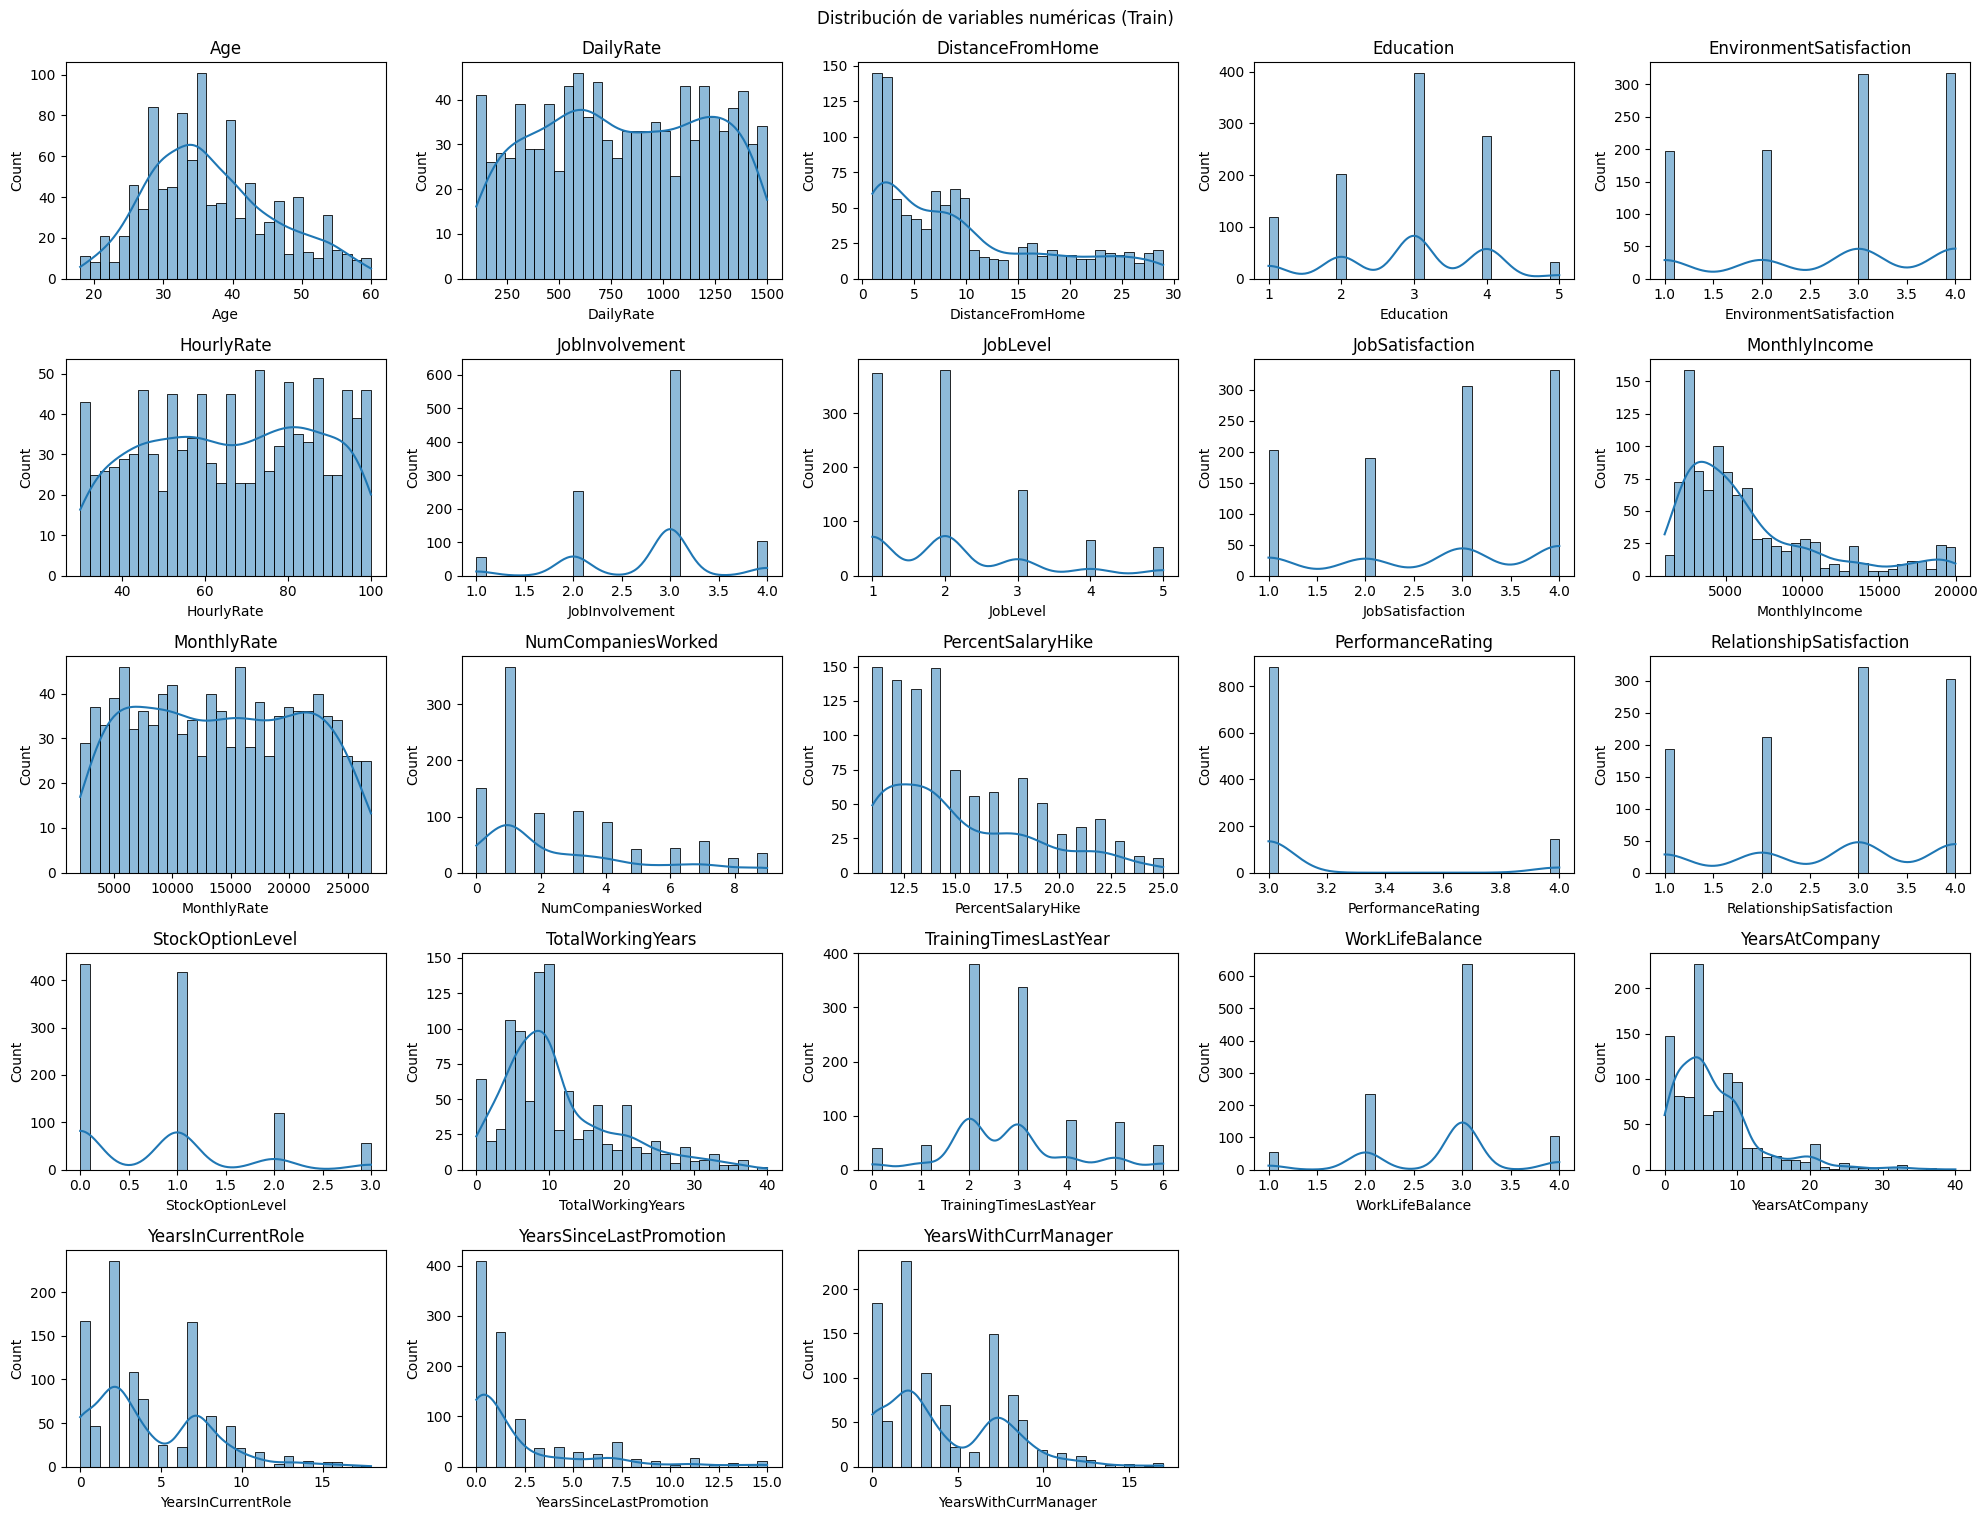

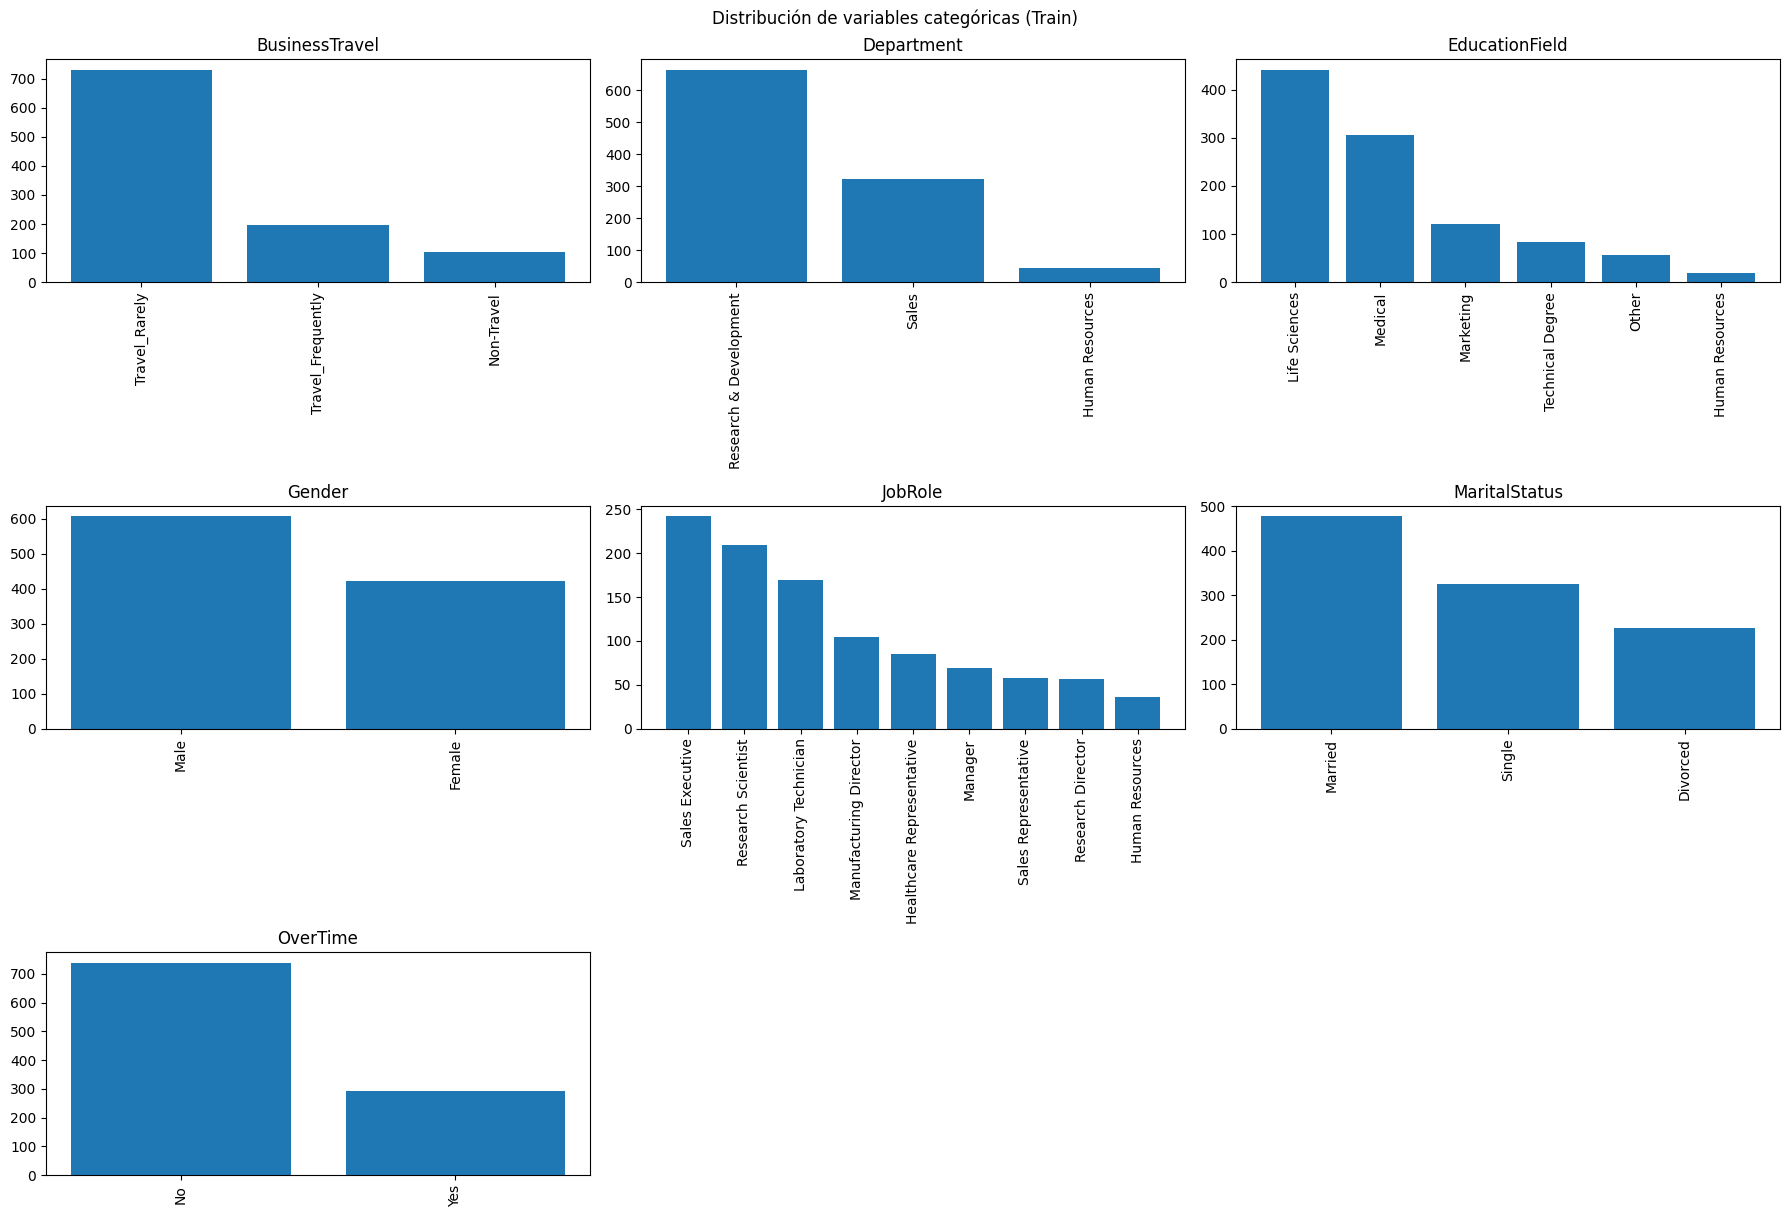

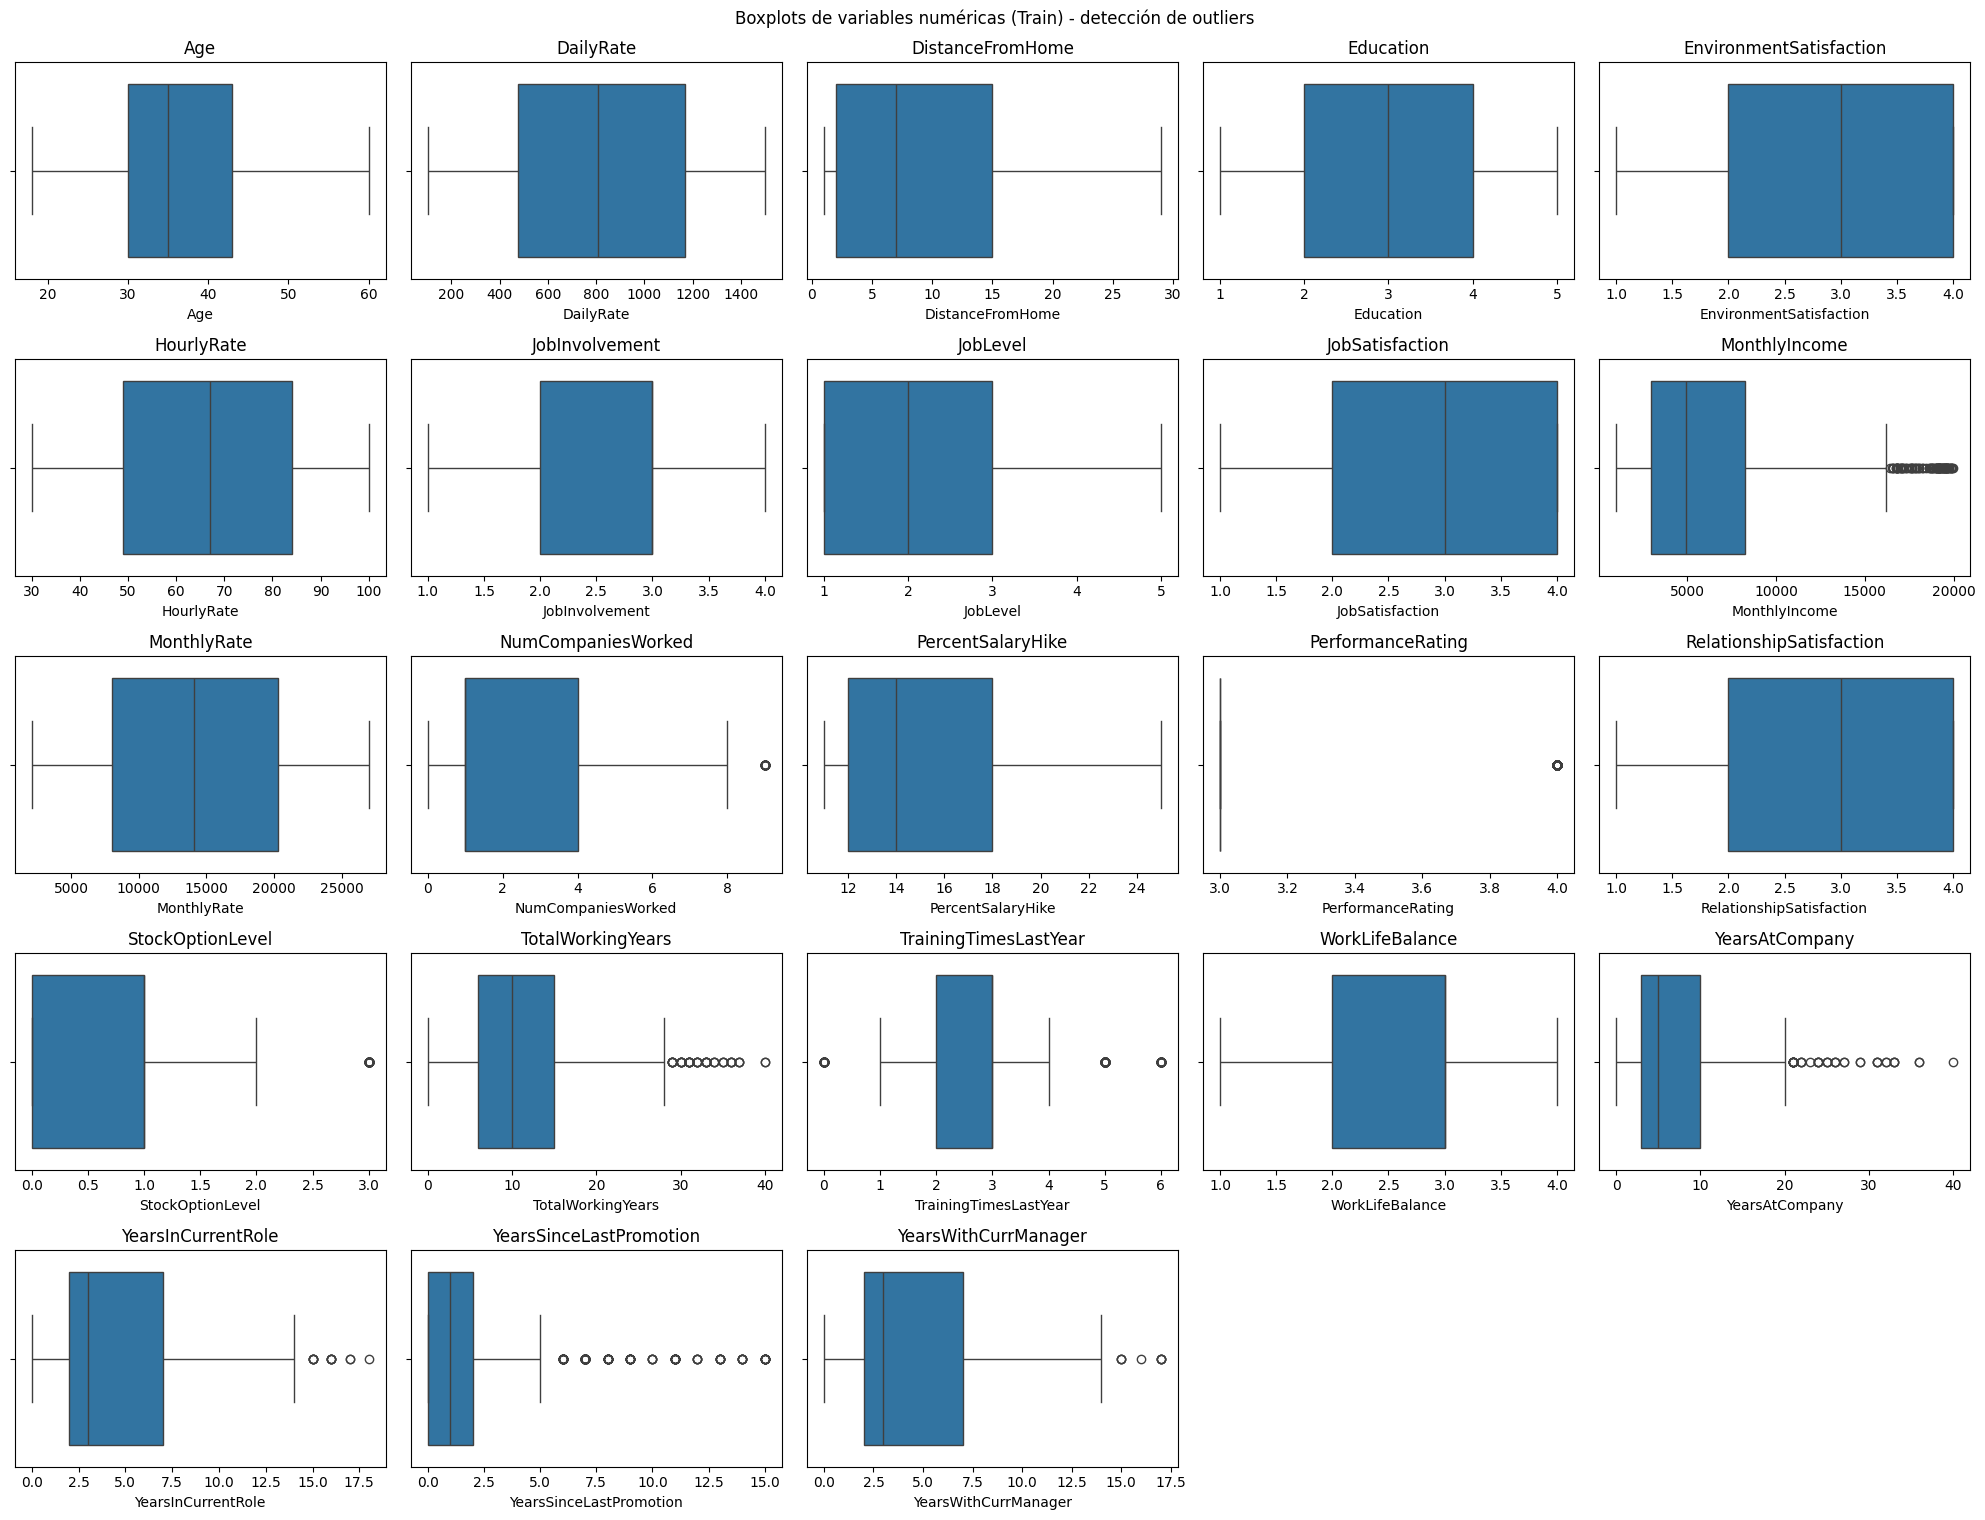


Estadísticas descriptivas de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
Age,1029.0,36.839650,9.096571,18.0,30.0,35.0,43.0,60.0
DailyRate,1029.0,811.583090,401.584530,102.0,474.0,809.0,1169.0,1499.0
DistanceFromHome,1029.0,9.491740,8.246753,1.0,2.0,7.0,15.0,29.0
Education,1029.0,2.903790,1.023781,1.0,2.0,3.0,4.0,5.0
EnvironmentSatisfaction,1029.0,2.733722,1.094308,1.0,2.0,3.0,4.0,4.0
HourlyRate,1029.0,66.236152,20.408084,30.0,49.0,67.0,84.0,100.0
JobInvolvement,1029.0,2.744412,0.706956,1.0,2.0,3.0,3.0,4.0
JobLevel,1029.0,2.071914,1.108281,1.0,1.0,2.0,3.0,5.0
JobSatisfaction,1029.0,2.745384,1.108549,1.0,2.0,3.0,4.0,4.0
MonthlyIncome,1029.0,6519.171040,4695.767631,1009.0,2974.0,4969.0,8268.0,19973.0



Sesgo (skewness) de variables numéricas:
PerformanceRating           2.055628
YearsSinceLastPromotion     2.039782
YearsAtCompany              1.813217
MonthlyIncome               1.394044
TotalWorkingYears           1.157577
NumCompaniesWorked          1.080789
JobLevel                    1.047628
StockOptionLevel            0.924751
DistanceFromHome            0.889646
YearsInCurrentRole          0.868755
PercentSalaryHike           0.835244
YearsWithCurrManager        0.750367
TrainingTimesLastYear       0.510386
Age                         0.426284
MonthlyRate                 0.039405
DailyRate                  -0.019677
HourlyRate                 -0.067444
Education                  -0.275299
RelationshipSatisfaction   -0.303544
EnvironmentSatisfaction    -0.337055
JobSatisfaction            -0.352045
JobInvolvement             -0.518246
WorkLifeBalance            -0.594951
dtype: float64


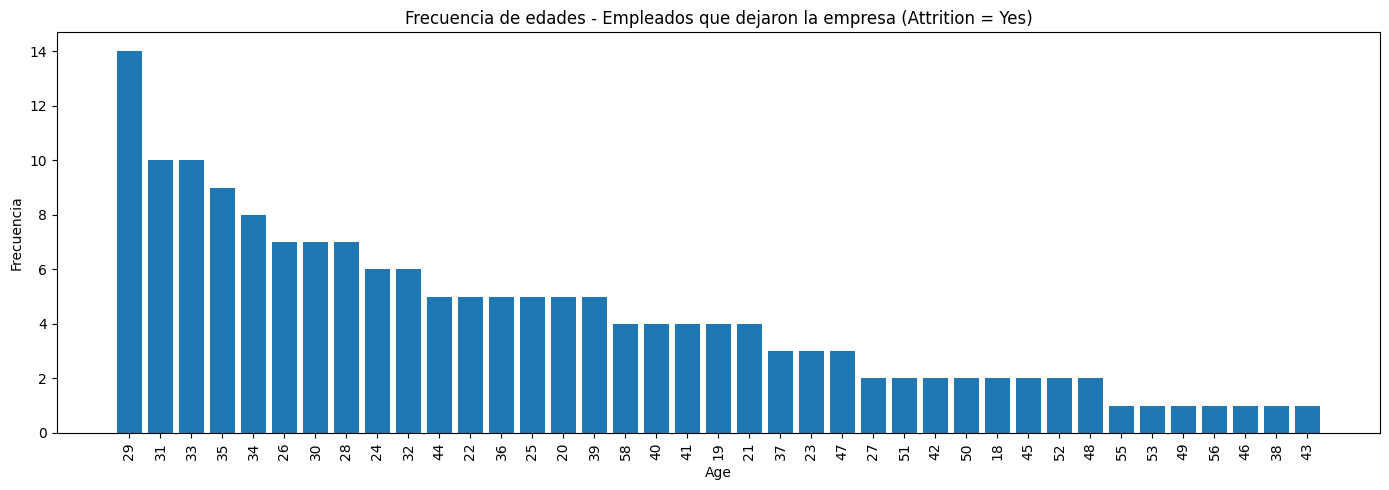

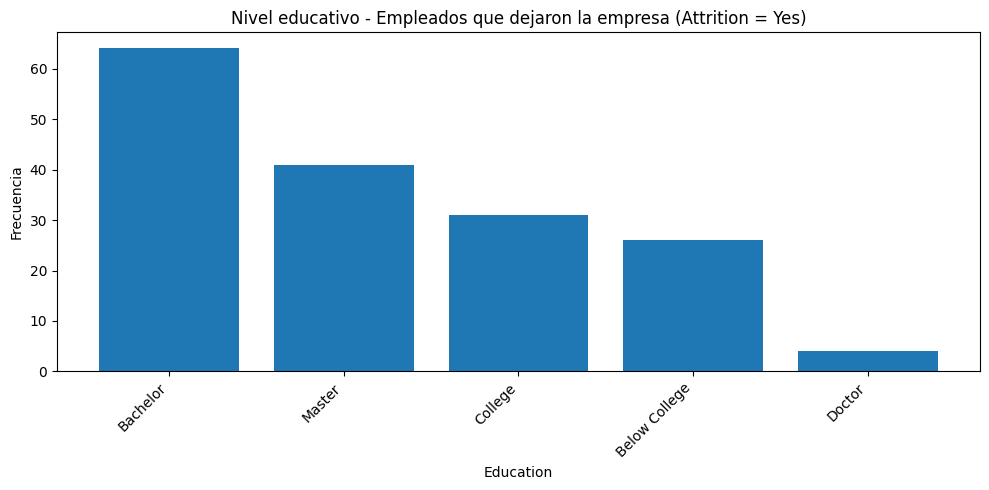

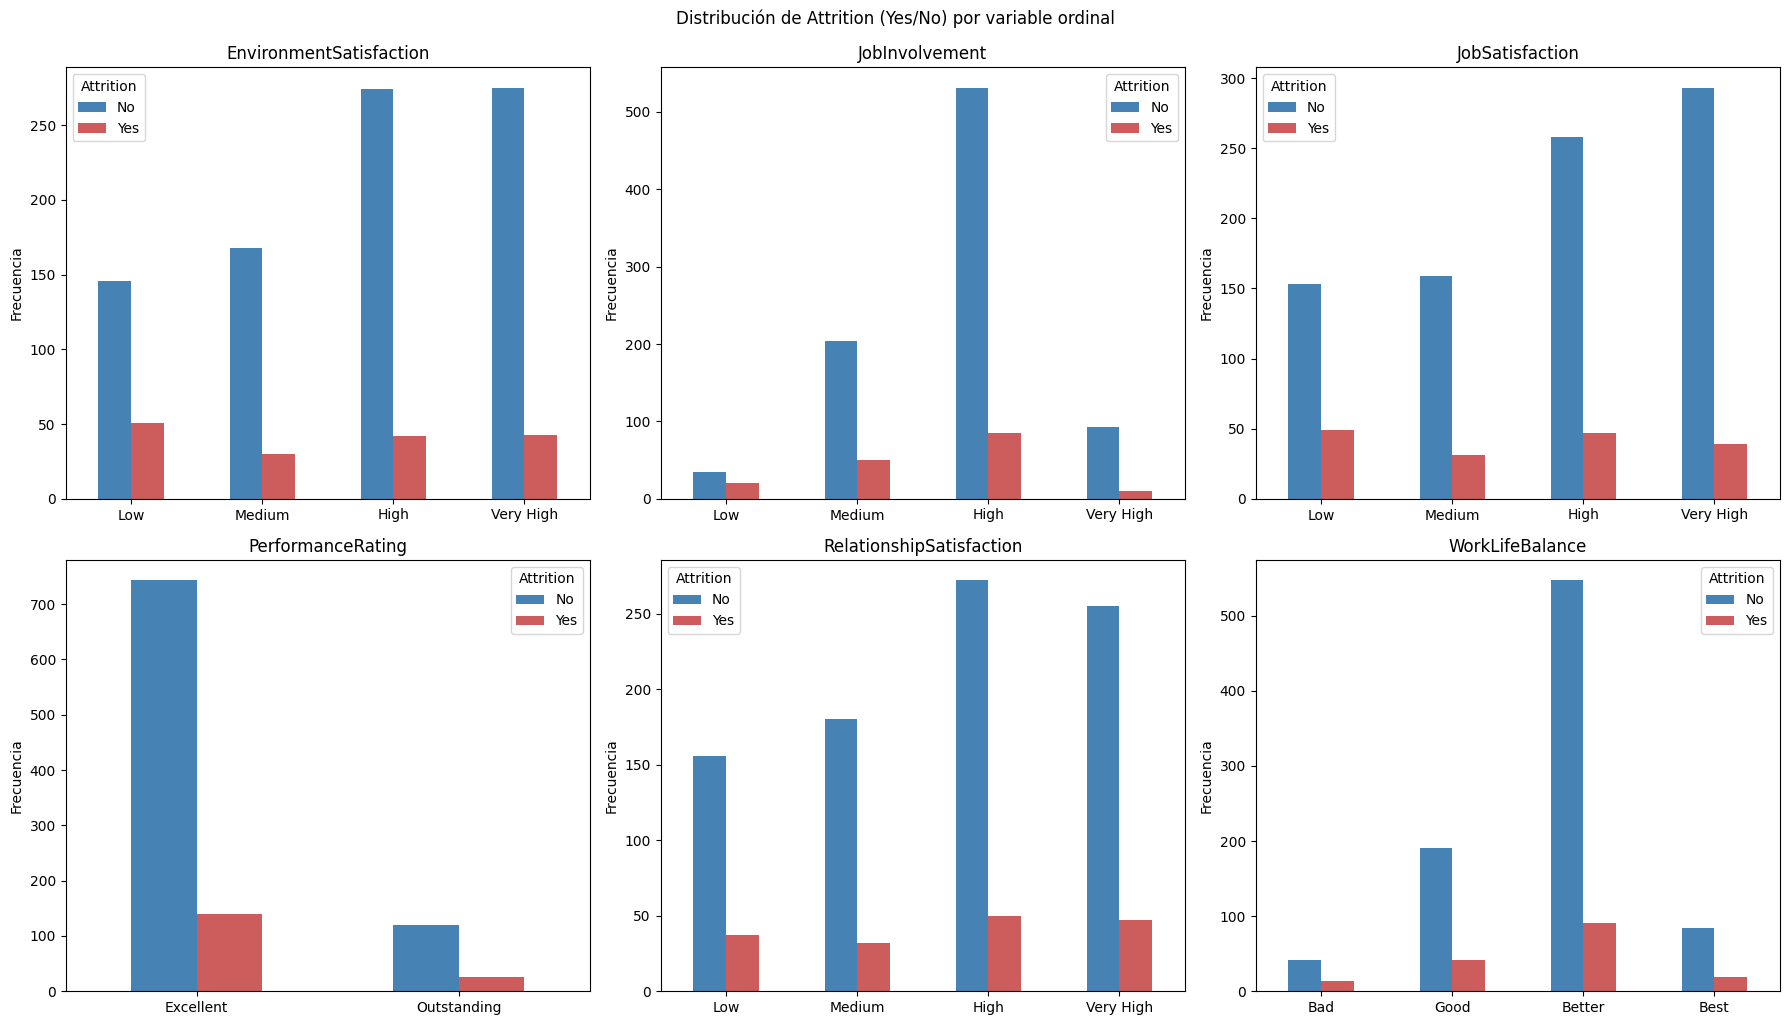

In [7]:
# Análisis y gráficos

# 1. Resumen general: tipos de variable y valores únicos
print(Xtrain.info())
print('='*100)

print("\nResumen de valores únicos por columna:")
resumen = pd.DataFrame({
    'tipo': Xtrain.dtypes,
    'valores_unicos': Xtrain.nunique(),
    '%_valor_mas_frecuente': [Xtrain[col].value_counts(normalize=True).max()*100 for col in Xtrain.columns]
})
display(resumen.sort_values(['tipo','valores_unicos']))
print('='*100)

# 2. Separar numéricas y categóricas
num_cols = Xtrain.select_dtypes(include=['int64', 'float64'])
cat_cols = Xtrain.select_dtypes(include=['object'])

# 3. Histogramas de variables numéricas - para ver sesgo y escala
n = len(num_cols.columns)
ncols = 5
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*3))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.histplot(data=Xtrain, x=col, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'{col}')

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Distribución de variables numéricas (Train)', y=1.01)
plt.show()

# 4. Gráficas de barras de variables categóricas - para ver balance de categorías
n_cat = len(cat_cols.columns)
ncols_cat = 3
nrows_cat = math.ceil(n_cat / ncols_cat)
fig, axes = plt.subplots(nrows_cat, ncols_cat, figsize=(18, nrows_cat*4))
axes = axes.flatten()

for i, col in enumerate(cat_cols.columns):
    counts = Xtrain[col].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=90)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Distribución de variables categóricas (Train)', y=1.01)
plt.show()

# 5. Boxplots de numéricas - para ver outliers
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*3))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.boxplot(data=Xtrain, x=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Boxplots de variables numéricas (Train) - detección de outliers', y=1.01)
plt.show()

# 6. Estadísticas descriptivas
print("\nEstadísticas descriptivas de variables numéricas:")
display(num_cols.describe().T)

# 7. Sesgo (skewness) de cada variable numérica - para decidir Yeo-Johnson
print("\nSesgo (skewness) de variables numéricas:")
sesgo = num_cols.skew().sort_values(ascending=False)
print(sesgo)

print('='*100)

# Edad de quienes dejaron la empresa
# Unimos temporalmente X_train con la variable de salida ya codificada, solo para poder filtrar por Attrition en este análisis exploratorio
df_temp = Xtrain.copy()
df_temp['Attrition'] = ytrainT.values

# Filtramos solo empleados que dejaron la empresa (Attrition = 1, "Yes")
edades_attrition_yes = df_temp[df_temp['Attrition'] == 1]['Age']

# Contamos frecuencias por edad y ordenamos de mayor a menor frecuencia
frecuencias = edades_attrition_yes.value_counts().sort_values(ascending=False)

# Graficamos
plt.figure(figsize=(14, 5))
plt.bar(frecuencias.index.astype(str), frecuencias.values)
plt.title('Frecuencia de edades - Empleados que dejaron la empresa (Attrition = Yes)')
plt.xlabel('Age')
plt.ylabel('Frecuencia')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print('='*100)

# Nivel educativo de quienes dejaron la empresa

# Diccionario de mapeo, según Kaggle
mapa_education = {
    1: 'Below College',
    2: 'College',
    3: 'Bachelor',
    4: 'Master',
    5: 'Doctor'
}

# Reutilizamos df_temp (Xtrain + Attrition ya unidos)
# Filtramos solo empleados que dejaron la empresa
educ_attrition_yes = df_temp[df_temp['Attrition'] == 1]['Education']

# Contamos frecuencias y ordenamos de mayor a menor
frecuencias_educ = educ_attrition_yes.value_counts().sort_values(ascending=False)

# Reemplazamos los números por las etiquetas de Kaggle, manteniendo el orden ya establecido
etiquetas = [mapa_education[val] for val in frecuencias_educ.index]

# Graficamos
plt.figure(figsize=(10, 5))
plt.bar(etiquetas, frecuencias_educ.values)
plt.title('Nivel educativo - Empleados que dejaron la empresa (Attrition = Yes)')
plt.xlabel('Education')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print('='*100)

# Attrition por variable ordinal
mapas = {
    'EnvironmentSatisfaction': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'JobInvolvement': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'JobSatisfaction': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'PerformanceRating': {1: 'Low', 2: 'Good', 3: 'Excellent', 4: 'Outstanding'},
    'RelationshipSatisfaction': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'WorkLifeBalance': {1: 'Bad', 2: 'Good', 3: 'Better', 4: 'Best'}
}

variables = list(mapas.keys())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, var in enumerate(variables):
    # Tabla de conteos: filas = niveles de la variable, columnas = Attrition (0/1)
    tabla = pd.crosstab(df_temp[var], df_temp['Attrition'])

    # Reemplazamos el índice numérico por las etiquetas correspondientes
    tabla.index = [mapas[var][val] for val in tabla.index]

    # Renombramos columnas para que la leyenda sea clara
    tabla = tabla.rename(columns={0: 'No', 1: 'Yes'})

    tabla.plot(kind='bar', ax=axes[i], color=['steelblue', 'indianred'])
    axes[i].set_title(var)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(title='Attrition')

plt.tight_layout()
plt.suptitle('Distribución de Attrition (Yes/No) por variable ordinal', y=1.02)
plt.show()


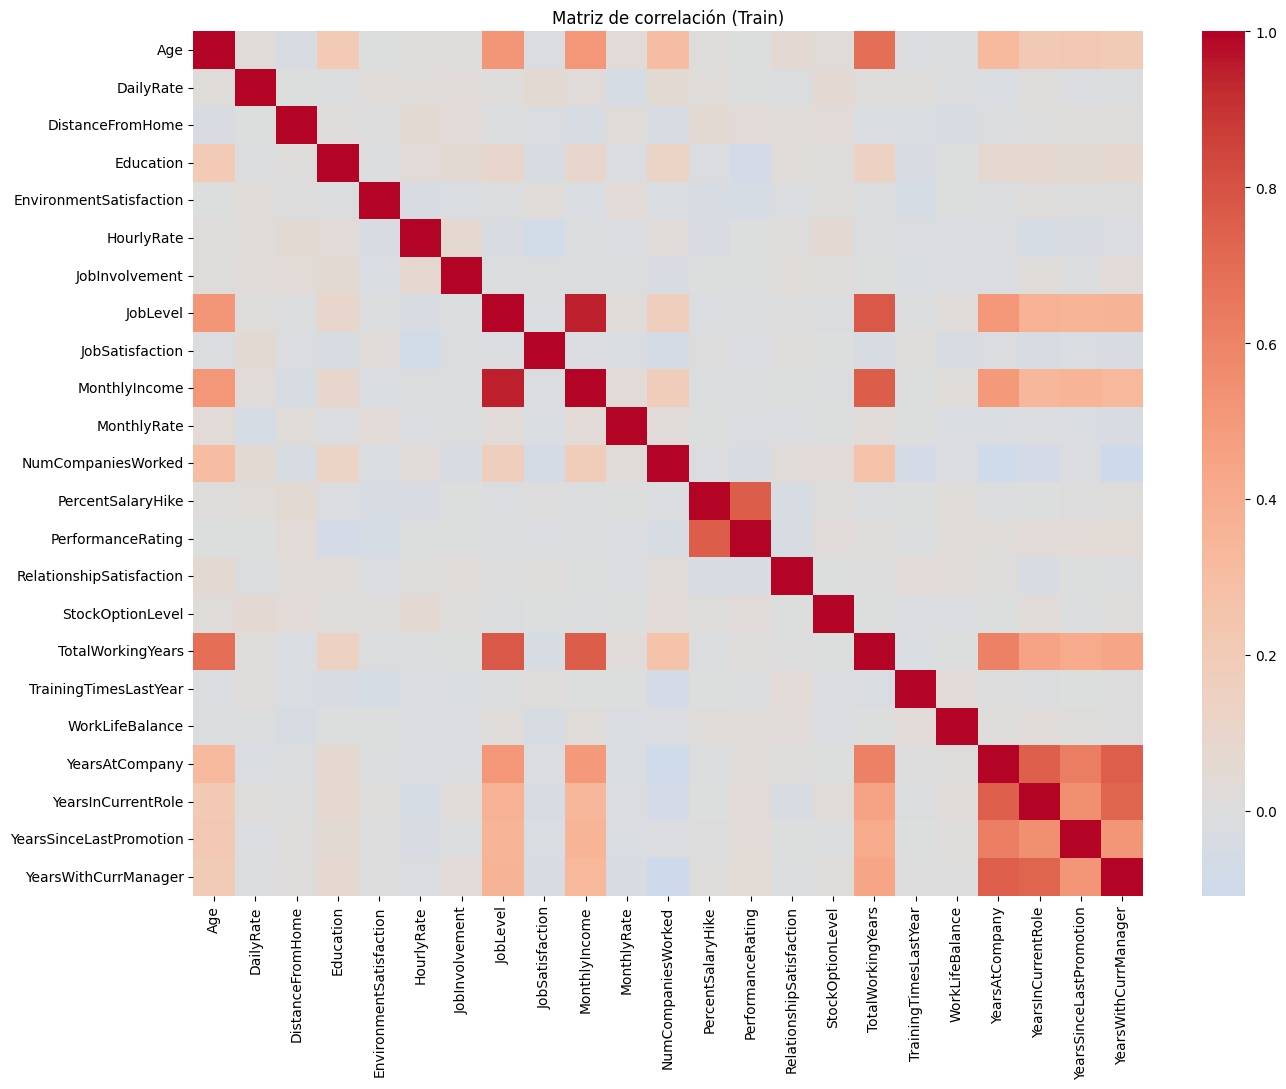

Pares con |r| > 0.7:


,var1,var2,r
134,JobLevel,MonthlyIncome,0.950029
141,JobLevel,TotalWorkingYears,0.770934
168,MonthlyIncome,TotalWorkingYears,0.764900
198,PercentSalaryHike,PerformanceRating,0.764425
249,YearsAtCompany,YearsWithCurrManager,0.756956
247,YearsAtCompany,YearsInCurrentRole,0.755669
251,YearsInCurrentRole,YearsWithCurrManager,0.730480



VIF (valores > 5 sugieren multicolinealidad relevante):


,VIF
JobLevel,11.148553
MonthlyIncome,10.945099
TotalWorkingYears,4.565745
YearsAtCompany,4.280327
YearsInCurrentRole,2.802285
YearsWithCurrManager,2.768123
PerformanceRating,2.458351
PercentSalaryHike,2.444700
Age,2.072269
YearsSinceLastPromotion,1.704996



Tasa de rotación por OverTime:


,tasa_rotacion,n
OverTime,,
Yes,0.323,291
No,0.098,738


... (4 outputs left out)


Tasa de rotación por Department:


,tasa_rotacion,n
Department,,
Sales,0.217,322
Human Resources,0.209,43
Research & Development,0.131,664



Tasa de rotación por JobRole:


,tasa_rotacion,n
JobRole,,
Sales Representative,0.448,58
Human Resources,0.250,36
Laboratory Technician,0.213,169
Sales Executive,0.174,242
Research Scientist,0.163,209
Manufacturing Director,0.077,104
Healthcare Representative,0.071,85
Manager,0.058,69
Research Director,0.018,57


In [8]:
# Relación entre variables y multicolinealidad (solo con Train)
num_ord = Xtrain.select_dtypes(include=['int64', 'float64'])

# 1. Matriz de correlación
corr = num_ord.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Matriz de correlación (Train)')
plt.tight_layout()
plt.show()

# 2. Pares de variables muy correlacionadas (|r| > 0.7)
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pares.columns = ['var1', 'var2', 'r']
print("Pares con |r| > 0.7:")
display(pares[pares['r'].abs() > 0.7].sort_values('r', key=lambda s: s.abs(), ascending=False))

# 3. Factor de inflación de la varianza (VIF), calculado con la inversa de la matriz de correlación
Z = (num_ord - num_ord.mean()) / num_ord.std()
vif = pd.Series(np.diag(np.linalg.pinv(np.corrcoef(Z.values, rowvar=False))),
                index=num_ord.columns, name='VIF').sort_values(ascending=False)
print("\nVIF (valores > 5 sugieren multicolinealidad relevante):")
display(vif.to_frame().head(10))

# 4. Tasa de rotación por categoría (Train)
df_tasa = Xtrain.copy()
df_tasa['Attrition'] = ytrainT['Attrition']
for col in ['OverTime', 'BusinessTravel', 'MaritalStatus', 'Department', 'JobRole']:
    print(f"\nTasa de rotación por {col}:")
    display(df_tasa.groupby(col)['Attrition'].agg(tasa_rotacion='mean', n='count')
            .sort_values('tasa_rotacion', ascending=False).round(3))


**Hallazgos que guían el modelado**

- Varias variables numéricas tienen sesgo positivo marcado (por ejemplo `YearsSinceLastPromotion` 2.04, `YearsAtCompany` 1.81 y `MonthlyIncome` 1.39), lo que justifica una transformación Yeo-Johnson.
- Hay multicolinealidad fuerte: `JobLevel` y `MonthlyIncome` tienen r = 0.95 y VIF cercano a 11, y `YearsAtCompany`, `YearsInCurrentRole` y `YearsWithCurrManager` se correlacionan entre sí (r entre 0.73 y 0.76). Esto vuelve inestables los coeficientes individuales.
- Las tasas de rotación en Train difieren mucho por categoría: 32% con tiempo extra contra 10% sin él; 27% entre solteros contra 9% entre divorciados; 45% entre Sales Representatives contra 2% entre Research Directors.
- Un falso negativo (perder a alguien sin intervenir) cuesta más que un falso positivo (una conversación de retención que no hacía falta), así que conviene priorizar el recall.

## 7. Preprocesamiento

Un `ColumnTransformer` aplica a cada tipo de variable su transformación dentro de un `Pipeline`, de modo que todo se reajusta en cada fold de la validación cruzada (sin fuga de datos):

| Tipo | Transformación |
|---|---|
| Numéricas (14) | mediana + Yeo-Johnson + estandarización |
| Ordinales (9) | moda + estandarización |
| Binarias (2) | moda + codificación ordinal |
| Nominales (5) | moda + one-hot (`drop='first'`) |

Train y Validation se reúnen en un solo conjunto (`Xtv`, `ytv`) porque se usará validación cruzada.

In [9]:
# NUMÉRICAS: imputación (mediana) + corrección de sesgo (Yeo-Johnson, que ya incluye escalamiento)
numericas_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('yeojohnson', PowerTransformer(method='yeo-johnson', standardize=True))])
numericas_pipeline_nombres = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate',
                              'NumCompaniesWorked', 'PercentSalaryHike','TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany',
                              'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

# ORDINALES: imputación (moda, ya que son categorías discretas con orden) + ya son numéricas con orden real, solo se escalan (no se codifican de nuevo)
catOrd_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('scaler', StandardScaler())])
catOrd_pipeline_nombres = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel','JobSatisfaction',
                           'PerformanceRating', 'RelationshipSatisfaction','WorkLifeBalance', 'StockOptionLevel']

# BINARIAS: imputación (moda) + codificación ordinal
catBin_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder())])
catBin_pipeline_nombres = ['Gender', 'OverTime']

# NOMINALES: imputación (moda) + One-Hot Encoding (sin orden entre categorías)
catNom_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])
catNom_pipeline_nombres = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']


columnasTransformer = ColumnTransformer([
    ('num', numericas_pipeline, numericas_pipeline_nombres),
    ('ord', catOrd_pipeline, catOrd_pipeline_nombres),
    ('bin', catBin_pipeline, catBin_pipeline_nombres),
    ('nom', catNom_pipeline, catNom_pipeline_nombres)
])


In [10]:
Xtv = pd.concat([Xtrain, Xval], axis=0)
ytv = pd.concat([ytrainT, yvalT], axis=0)


print("Dimensión del conjunto Train+Val:")
print(Xtv.shape)
print(ytv.shape)


Dimensión del conjunto Train+Val:
(1249, 30)
(1249, 1)


## 8. Comparación de modelos y ajuste de hiperparámetros

Se comparan regresión logística sin penalización, Lasso (L1), Ridge (L2), ElasticNet y KNN con `GridSearchCV` (5 folds × 3 repeticiones, métrica accuracy). Los modelos elegidos se vuelven a evaluar con otras particiones (otra semilla) para reducir el optimismo de la selección. Todos usan `random_state=1`.

>> LR  acc=0.885 (0.018)  params={}
>> LASSO  acc=0.889 (0.017)  params={'C': 0.3}
>> RIDGE  acc=0.889 (0.020)  params={'C': 0.3}
>> EN  acc=0.889 (0.020)  params={'C': 1, 'l1_ratio': 0.3}
   AVISO: l1_ratio=0.3 quedó en el borde de la malla [0.3, 0.5, 0.7]; conviene ampliarla.
>> KNN  acc=0.849 (0.009)  params={'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}

Exactitud del modelo ingenuo en Train+Val: 0.8391


,mejores_hiperparametros,acc_busqueda,acc_evaluacion_media,acc_evaluacion_std,mejora_vs_baseline_pp
modelo,,,,,
LR,{},0.8855,0.8852,0.0179,4.6174
LASSO,{'C': 0.3},0.8898,0.8887,0.0171,4.9641
RIDGE,{'C': 0.3},0.8895,0.8887,0.0198,4.9648
EN,"{'C': 1, 'l1_ratio': 0.3}",0.8892,0.8887,0.0196,4.9644
KNN,"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}",0.8511,0.8487,0.0093,0.9614


Rango entre variantes logísticas: 0.0035 | desviación estándar máxima: 0.0198 -> diferencias dentro del ruido
LR: SUPERA el baseline por 4.62 puntos porcentuales
LASSO: SUPERA el baseline por 4.96 puntos porcentuales
RIDGE: SUPERA el baseline por 4.96 puntos porcentuales
EN: SUPERA el baseline por 4.96 puntos porcentuales
KNN: SUPERA el baseline por 0.96 puntos porcentuales


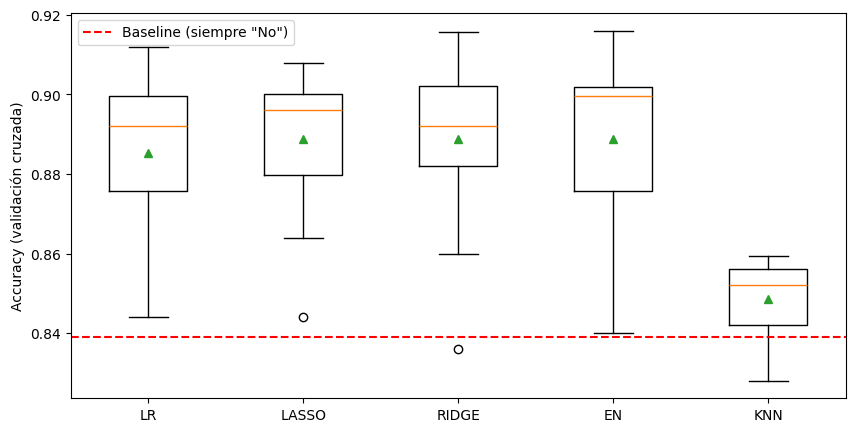

In [11]:
# Ajuste de hiperparámetros.
#     El preprocesamiento va DENTRO del Pipeline: se reajusta en cada fold de la validación
#     cruzada, así que no hay fuga de datos. Se mantiene random_state=1 en todos los modelos.

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

y_tv = np.ravel(ytv)
baseline_tv = 1 - y_tv.mean()      # exactitud del modelo ingenuo (siempre "No") en Train+Val

candidatos = {
    'LR':    (LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000, random_state=1), {}),
    'LASSO': (LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=1),
              {'m__C': [0.03, 0.1, 0.3, 1, 3, 10]}),
    'RIDGE': (LogisticRegression(penalty='l2', solver='liblinear', max_iter=1000, random_state=1),
              {'m__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]}),
    'EN':    (LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000, random_state=1),
              {'m__C': [0.1, 0.3, 1, 3], 'm__l1_ratio': [0.3, 0.5, 0.7]}),
    'KNN':   (KNeighborsClassifier(),
              {'m__n_neighbors': [3, 5, 7, 11, 15, 21, 31], 'm__weights': ['uniform', 'distance'], 'm__p': [1, 2]}),
}

cv_busqueda   = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)    # elige hiperparámetros
cv_evaluacion = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=11)   # re-evalúa con otras particiones

resultados, nombres, filas = [], [], []
for nombre, (modelo, grid) in candidatos.items():
    pipe = Pipeline([('ct', columnasTransformer), ('m', modelo)])
    gs = GridSearchCV(pipe, grid, cv=cv_busqueda, scoring='accuracy', n_jobs=-1)
    gs.fit(Xtv, y_tv)

    scores = cross_val_score(gs.best_estimator_, Xtv, y_tv, scoring='accuracy', cv=cv_evaluacion, n_jobs=-1)
    resultados.append(scores)
    nombres.append(nombre)
    filas.append({'modelo': nombre,
                  'mejores_hiperparametros': {k.replace('m__', ''): v for k, v in gs.best_params_.items()},
                  'acc_busqueda': gs.best_score_,
                  'acc_evaluacion_media': scores.mean(),
                  'acc_evaluacion_std': scores.std(),
                  'mejora_vs_baseline_pp': 100 * (scores.mean() - baseline_tv)})
    print('>> %s  acc=%.3f (%.3f)  params=%s' % (nombre, scores.mean(), scores.std(), filas[-1]['mejores_hiperparametros']))
    for k, vals in grid.items():
        if len(vals) > 2 and gs.best_params_[k] in (min(vals), max(vals)):
            print(f"   AVISO: {k.replace('m__', '')}={gs.best_params_[k]} quedó en el borde de la malla {vals}; conviene ampliarla.")

tabla_modelos = pd.DataFrame(filas).set_index('modelo')
print("\nExactitud del modelo ingenuo en Train+Val: %.4f" % baseline_tv)
display(tabla_modelos.round(4))

# Resumen automático
logisticos = tabla_modelos.loc[['LR', 'LASSO', 'RIDGE', 'EN'], 'acc_evaluacion_media']
std_max = tabla_modelos.loc[['LR', 'LASSO', 'RIDGE', 'EN'], 'acc_evaluacion_std'].max()
print("Rango entre variantes logísticas: %.4f | desviación estándar máxima: %.4f -> %s" % (
      logisticos.max() - logisticos.min(), std_max,
      "diferencias dentro del ruido" if logisticos.max() - logisticos.min() < std_max else "hay diferencias mayores al ruido"))
for n in tabla_modelos.index:
    estado = "SUPERA" if tabla_modelos.loc[n, 'acc_evaluacion_media'] > baseline_tv else "NO supera"
    print(f"{n}: {estado} el baseline por {tabla_modelos.loc[n, 'mejora_vs_baseline_pp']:.2f} puntos porcentuales")

plt.figure(figsize=(10, 5))
plt.boxplot(resultados, showmeans=True)
plt.xticks(range(1, len(nombres) + 1), nombres)
plt.axhline(baseline_tv, color='red', linestyle='--', label='Baseline (siempre "No")')
plt.ylabel('Accuracy (validación cruzada)')
plt.legend()
plt.show()


Los cuatro modelos logísticos quedan entre 0.885 y 0.889 de accuracy, entre 4.6 y 5.0 puntos porcentuales por encima del baseline (0.839). La diferencia entre ellos (0.0035) es menor que su desviación estándar (hasta 0.020), así que no se pueden distinguir: la regularización no aportó una mejora medible sobre la regresión logística sin penalización. La búsqueda eligió `C = 0.3` para Lasso y Ridge, y `C = 1` con `l1_ratio = 0.3` para ElasticNet.

KNN llega a 0.849 (k = 5, distancia euclidiana, pesos uniformes): supera al baseline por solo 1.0 punto, es el peor modelo y la búsqueda no logró mejorarlo con esta malla. La dimensionalidad que introduce el one-hot combinada con el desbalance podría explicarlo, pero es una hipótesis que no se probó.

Se continúa con ElasticNet porque tiene el valor más alto (empatado con Lasso y Ridge) y combina ambas penalizaciones. Como solo 16% de los empleados se va, la exactitud no basta para evaluarlo: más adelante se miden recall, precisión, F1, ROC-AUC y PR-AUC.

## 9. Modelo final: ElasticNet

Se afina ElasticNet con una malla más amplia (`C` y `l1_ratio`), con el Pipeline completo dentro del `GridSearchCV`.

Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)
-----------------------------------------------------------------
Mejor modelo: 0.889242 usando los hiperparámetros {'m__C': 1, 'm__l1_ratio': 0.3}
Train mean(std): 90.65% (0.39%)
Val   mean(std): 88.92% (1.50%)
Brecha Train-Val: 1.72 puntos -> NO sobreentrenado (< 3 puntos)
Baseline (siempre "No"): 83.91% -> NO subentrenado


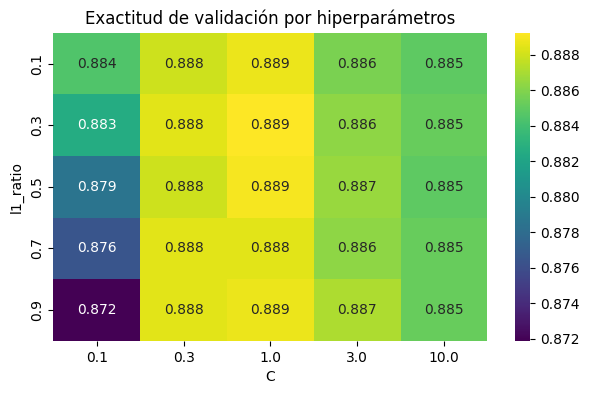

In [12]:
# Pipeline completo dentro del GridSearchCV: el preprocesamiento se ajusta solo con los datos
# de entrenamiento de cada fold (sin fuga de datos).
pipe_en = Pipeline([('ct', columnasTransformer),
                    ('m', LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000, random_state=1))])

dicc_grid = {
    'm__C': [0.1, 0.3, 1, 3, 10],
    'm__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

grid = GridSearchCV(estimator=pipe_en,
                    param_grid=dicc_grid,
                    cv=cv,
                    scoring='accuracy',
                    n_jobs=-1,
                    return_train_score=True)

resultado_malla = grid.fit(Xtv, np.ravel(ytv))

# Train y Validación DEL MEJOR modelo (no el promedio de toda la malla)
i = resultado_malla.best_index_
res = resultado_malla.cv_results_
train_m, train_s = res['mean_train_score'][i], res['std_train_score'][i]
val_m, val_s = res['mean_test_score'][i], res['std_test_score'][i]
baseline_tv = 1 - np.ravel(ytv).mean()

print("Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)")
print("-"*65)
print("Mejor modelo: %f usando los hiperparámetros %s" % (resultado_malla.best_score_, resultado_malla.best_params_))
print('Train mean(std): %.2f%% (%.2f%%)' % (100*train_m, 100*train_s))
print('Val   mean(std): %.2f%% (%.2f%%)' % (100*val_m, 100*val_s))
print('Brecha Train-Val: %.2f puntos -> %s' % (100*(train_m - val_m),
      'NO sobreentrenado (< 3 puntos)' if (train_m - val_m) < 0.03 else 'posible sobreentrenamiento (>= 3 puntos)'))
print('Baseline (siempre "No"): %.2f%% -> %s' % (100*baseline_tv,
      'NO subentrenado' if val_m > baseline_tv else 'SUBENTRENADO'))

# ¿El mejor valor quedó en el borde de la malla?
for p, vals in dicc_grid.items():
    b = resultado_malla.best_params_[p]
    if b in (min(vals), max(vals)):
        print(f"AVISO: {p}={b} quedó en el borde de la malla {vals}; conviene ampliarla.")

# Mapa de calor de la exactitud de validación sobre la malla
tabla = (pd.DataFrame({'C': [d['m__C'] for d in res['params']],
                       'l1_ratio': [d['m__l1_ratio'] for d in res['params']],
                       'acc_val': res['mean_test_score']})
         .pivot(index='l1_ratio', columns='C', values='acc_val'))
plt.figure(figsize=(7, 4))
sns.heatmap(tabla, annot=True, fmt='.3f', cmap='viridis')
plt.title('Exactitud de validación por hiperparámetros')
plt.show()


Mejor combinación: `C = 1`, `l1_ratio = 0.3`. La exactitud es 90.65% en Train y 88.92% en validación: una brecha de 1.7 puntos, por lo que no hay sobreajuste relevante, y supera al baseline (83.91%) por 5.0 puntos porcentuales.

## 10. Evaluación en Test

El Test se usa una sola vez, con el modelo reajustado en Train + Validation.

In [13]:
# Reporte de desempeño en Test

model_best = resultado_malla.best_estimator_      # Pipeline (preprocesamiento + modelo) ya reajustado con Train+Val
y_test = np.ravel(ytestT)
y_pred_test = model_best.predict(Xtest)

print(classification_report(y_test, y_pred_test, target_names=['No', 'Yes']))

def wilson_ci(k, n, z=1.96):
    """Intervalo de confianza de Wilson para una proporción k/n."""
    p = k / n
    d = 1 + z**2 / n
    c = p + z**2 / (2*n)
    a = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2))
    return (c - a)/d, (c + a)/d

n_test = len(y_test)
acc_test = metrics.accuracy_score(y_test, y_pred_test)
base_test = 1 - y_test.mean()
tp = int(((y_pred_test == 1) & (y_test == 1)).sum())
n_pos = int(y_test.sum())
lo, hi = wilson_ci(tp, n_pos)
lo_a, hi_a = wilson_ci(int(round(acc_test*n_test)), n_test)
print(f"Accuracy en Test: {acc_test:.3f} (IC95% {lo_a:.3f}-{hi_a:.3f}) vs. baseline {base_test:.3f} "
      f"-> diferencia de {100*(acc_test-base_test):.1f} puntos porcentuales")
print(f"Recall de 'Yes': {tp}/{n_pos} = {tp/n_pos:.3f} (IC95% {lo:.3f}-{hi:.3f}); con tan pocos casos positivos el intervalo es muy amplio.")


              precision    recall  f1-score   support

          No       0.89      0.95      0.92       185
         Yes       0.61      0.39      0.47        36

    accuracy                           0.86       221
   macro avg       0.75      0.67      0.70       221
weighted avg       0.84      0.86      0.85       221

Accuracy en Test: 0.860 (IC95% 0.808-0.899) vs. baseline 0.837 -> diferencia de 2.3 puntos porcentuales
Recall de 'Yes': 14/36 = 0.389 (IC95% 0.248-0.551); con tan pocos casos positivos el intervalo es muy amplio.


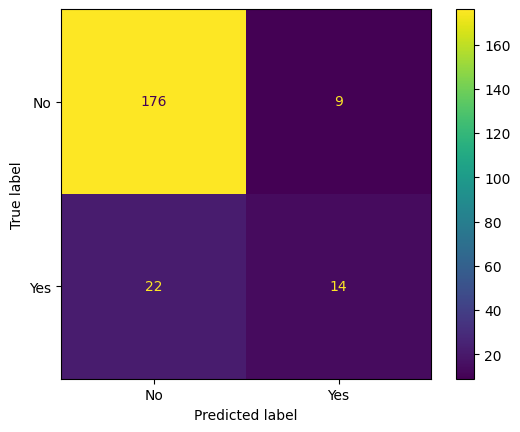

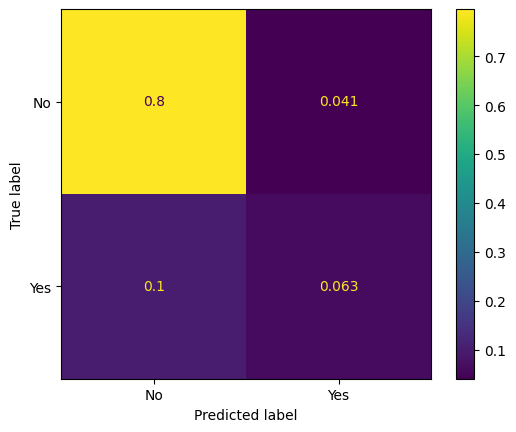

In [14]:
# Matriz de confusión en Test
ConfusionMatrixDisplay.from_estimator(model_best, Xtest, ytestT, display_labels=['No','Yes'])
plt.show()
ConfusionMatrixDisplay.from_estimator(model_best, Xtest, ytestT, display_labels=['No','Yes'], normalize='all')
plt.show()


In [15]:
# Valores de la matriz de confusión
vn, fp, fn, vp = metrics.confusion_matrix(y_test, y_pred_test).ravel()
N = vn + fp + fn + vp
print(f"VN = {vn} ({vn/N:.3f})   FP = {fp} ({fp/N:.3f})   FN = {fn} ({fn/N:.3f})   VP = {vp} ({vp/N:.3f})")
print(f"Exactitud = (VN+VP)/N = {(vn+vp)/N:.3f}")
print(f"Recall de 'Yes' = VP/(VP+FN) = {vp/(vp+fn):.3f}  -> no se detecta al {100*fn/(vp+fn):.1f}% de quienes sí se fueron")
print(f"Precisión de 'Yes' = VP/(VP+FP) = {vp/(vp+fp):.3f}")


VN = 176 (0.796)   FP = 9 (0.041)   FN = 22 (0.100)   VP = 14 (0.063)
Exactitud = (VN+VP)/N = 0.860
Recall de 'Yes' = VP/(VP+FN) = 0.389  -> no se detecta al 61.1% de quienes sí se fueron
Precisión de 'Yes' = VP/(VP+FP) = 0.609


**Resultados en Test** (221 empleados, 36 de los cuales se fueron)

- Matriz de confusión: VN = 176, FP = 9, FN = 22, VP = 14.
- La exactitud es 0.860 contra un baseline de 0.837: una ventaja de 2.3 puntos porcentuales cuyo intervalo de confianza al 95% (0.81 a 0.90) incluye al baseline. Con esta muestra no se puede afirmar que el modelo supere al ingenuo en exactitud.
- Lo que importa es la clase "se va": el modelo detecta 14 de 36 salidas (recall 0.39, IC 95% de 0.25 a 0.55) y deja sin detectar a 22 (61%). De sus 23 alertas, 14 son correctas (precisión 0.61).
- El error dominante es el falso negativo (22 contra 9), lo contrario de lo que conviene según el costo de los errores.

## 11. Factores asociados con la rotación

In [16]:
# Importancia de factores (coeficientes del modelo)
nombres_feat = model_best.named_steps['ct'].get_feature_names_out()
coefs = model_best.named_steps['m'].coef_.ravel()
importancia = (pd.DataFrame({'importance': coefs}, index=nombres_feat)
               .sort_values(by='importance', ascending=False))
display(importancia)

print("Top 5 que AUMENTAN la probabilidad de rotación:")
print(importancia.head(5).round(3).to_string())
print("\nTop 5 que la DISMINUYEN:")
print(importancia.tail(5).iloc[::-1].round(3).to_string())

protegidas_en_modelo = [n for n in importancia.index if any(p in n for p in ['Age', 'Gender', 'MaritalStatus'])]
print("\nVariables protegidas presentes en este modelo:")
print(importancia.loc[protegidas_en_modelo].round(3).to_string())


,importance
bin__OverTime,2.084316
nom__BusinessTravel_Travel_Frequently,1.634004
nom__MaritalStatus_Single,0.994959
nom__JobRole_Laboratory Technician,0.683032
nom__BusinessTravel_Travel_Rarely,0.602515
num__YearsAtCompany,0.546345
nom__EducationField_Technical Degree,0.526100
num__NumCompaniesWorked,0.507927
num__DistanceFromHome,0.419522
num__YearsSinceLastPromotion,0.330094


Top 5 que AUMENTAN la probabilidad de rotación:
                                       importance
bin__OverTime                               2.084
nom__BusinessTravel_Travel_Frequently       1.634
nom__MaritalStatus_Single                   0.995
nom__JobRole_Laboratory Technician          0.683
nom__BusinessTravel_Travel_Rarely           0.603

Top 5 que la DISMINUYEN:
                                importance
num__MonthlyIncome                  -0.563
nom__JobRole_Research Director      -0.555
ord__EnvironmentSatisfaction        -0.530
num__YearsInCurrentRole             -0.513
ord__JobInvolvement                 -0.468

Variables protegidas presentes en este modelo:
                            importance
nom__MaritalStatus_Single        0.995
bin__Gender                      0.302
nom__MaritalStatus_Married       0.177
num__Age                        -0.306


Un coeficiente positivo aumenta la probabilidad de renuncia (en log-odds) y uno negativo la reduce.

- **Aumentan el riesgo:** trabajar tiempo extra (`OverTime`, 2.08), viajar con frecuencia (1.63, frente a no viajar), ser soltero (0.99, frente a divorciado) y ser Laboratory Technician (0.68). Es coherente con las tasas observadas en Train (32% de rotación con tiempo extra contra 10% sin él).
- **Reducen el riesgo:** mayor ingreso mensual (-0.56), ser Research Director (-0.56), mayor satisfacción con el ambiente (-0.53) y más años en el puesto actual (-0.51).

Cuatro precauciones al interpretarlos:

1. Son asociaciones, no causas, y el dataset es sintético.
2. Con variables correlacionadas los coeficientes son inestables: `MonthlyIncome` y `JobLevel` tienen VIF cercano a 11 y `YearsAtCompany` sale positivo (+0.55) mientras `YearsInCurrentRole` sale negativo. Conviene apoyarse más en las tasas observadas que en un coeficiente aislado.
3. Las variables numéricas están estandarizadas y las dummies no, así que sus magnitudes no son estrictamente comparables.
4. Con `drop='first'`, cada dummy se compara contra la categoría eliminada.

**Alerta ética:** `MaritalStatus_Single` es el tercer factor más fuerte, y Gender (+0.30) y Age (-0.31) también participan en el modelo. La siguiente sección mide qué pasa al quitarlas.

## 12. Más allá de la exactitud: umbral, class_weight y variables sensibles

Hasta aquí se optimizó la exactitud, pero el error más costoso es el falso negativo. Esta sección responde tres preguntas:

1. ¿Qué se gana cambiando el umbral de decisión (en vez de 0.5) o usando `class_weight='balanced'`?
2. ¿Cuánto se pierde al quitar Age, Gender y MaritalStatus?
3. ¿El modelo detecta igual de bien a distintos grupos (género, estado civil, edad)?

Reglas para no hacer trampa: el umbral se elige con predicciones fuera de muestra (out-of-fold) sobre Train + Validation usando F2 (el recall pesa el doble que la precisión). El Test no se usa para elegir nada: se reporta como evaluación descriptiva.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

PROTEGIDAS = ['Age', 'Gender', 'MaritalStatus']
mejor_C  = resultado_malla.best_params_['m__C']
mejor_l1 = resultado_malla.best_params_['m__l1_ratio']
y_tv = np.ravel(ytv)
y_test = np.ravel(ytestT)

def make_ct(excluir=()):
    """Mismo preprocesamiento de la sección 7, pudiendo excluir columnas."""
    bloques = [('num', numericas_pipeline, numericas_pipeline_nombres),
               ('ord', catOrd_pipeline, catOrd_pipeline_nombres),
               ('bin', catBin_pipeline, catBin_pipeline_nombres),
               ('nom', catNom_pipeline, catNom_pipeline_nombres)]
    out = []
    for nombre, pipe, cols in bloques:
        cols = [c for c in cols if c not in excluir]
        if cols:
            out.append((nombre, pipe, cols))
    return ColumnTransformer(out)

def make_pipe(excluir=(), class_weight=None):
    return Pipeline([('ct', make_ct(excluir)),
                     ('m', LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=mejor_l1, C=mejor_C,
                                              class_weight=class_weight, max_iter=5000, random_state=1))])

def umbral_f2(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    f2 = (5 * prec * rec) / (4 * prec + rec + 1e-12)
    return float(thr[np.argmax(f2)])

def calcula_metricas(y, p, umbral):
    pred = (p >= umbral).astype(int)
    return {'umbral': round(umbral, 3),
            'accuracy': metrics.accuracy_score(y, pred),
            'precision': metrics.precision_score(y, pred, zero_division=0),
            'recall': metrics.recall_score(y, pred),
            'F1': metrics.f1_score(y, pred),
            'ROC-AUC': roc_auc_score(y, p),
            'PR-AUC': average_precision_score(y, p),
            'alertas': int(pred.sum())}

escenarios = {
    'A) Base, umbral 0.5':                         dict(excluir=(),         class_weight=None,       tune=False),
    'B) class_weight=balanced, umbral 0.5':        dict(excluir=(),         class_weight='balanced', tune=False),
    'C) Base, umbral optimizado (F2)':             dict(excluir=(),         class_weight=None,       tune=True),
    'D) Sin protegidas, umbral optimizado (F2)':   dict(excluir=PROTEGIDAS, class_weight=None,       tune=True),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
oof_probs, umbrales, tabla_oof, tabla_test = {}, {}, [], []

for nombre, cfg in escenarios.items():
    pipe = make_pipe(cfg['excluir'], cfg['class_weight'])
    p_oof = cross_val_predict(pipe, Xtv, y_tv, cv=skf, method='predict_proba')[:, 1]
    umbral = umbral_f2(y_tv, p_oof) if cfg['tune'] else 0.5
    oof_probs[nombre], umbrales[nombre] = p_oof, umbral
    tabla_oof.append({'escenario': nombre, **calcula_metricas(y_tv, p_oof, umbral)})

    pipe.fit(Xtv, y_tv)
    p_test = pipe.predict_proba(Xtest)[:, 1]
    tabla_test.append({'escenario': nombre, **calcula_metricas(y_test, p_test, umbral)})

tabla_oof = pd.DataFrame(tabla_oof).set_index('escenario')
tabla_test = pd.DataFrame(tabla_test).set_index('escenario')

print("Train+Val, predicciones fuera de muestra (el umbral optimizado se eligió aquí, así que es algo optimista):")
display(tabla_oof.round(3))
print(f"Test ({len(y_test)} empleados, {int(y_test.sum())} que se fueron). Descriptivo: no se usó para elegir umbral ni escenario:")
display(tabla_test.round(3))
print(f"Baseline de Test (accuracy, siempre 'No'): {1 - y_test.mean():.3f}")


Train+Val, predicciones fuera de muestra (el umbral optimizado se eligió aquí, así que es algo optimista):


,umbral,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,alertas
escenario,,,,,,,,
"A) Base, umbral 0.5",0.500,0.889,0.750,0.463,0.572,0.845,0.643,124
"B) class_weight=balanced, umbral 0.5",0.500,0.774,0.392,0.731,0.510,0.834,0.612,375
"C) Base, umbral optimizado (F2)",0.157,0.783,0.407,0.761,0.530,0.845,0.643,376
"D) Sin protegidas, umbral optimizado (F2)",0.176,0.790,0.416,0.746,0.534,0.842,0.633,361


Test (221 empleados, 36 que se fueron). Descriptivo: no se usó para elegir umbral ni escenario:


,umbral,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,alertas
escenario,,,,,,,,
"A) Base, umbral 0.5",0.500,0.860,0.609,0.389,0.475,0.727,0.504,23
"B) class_weight=balanced, umbral 0.5",0.500,0.688,0.296,0.667,0.410,0.715,0.464,81
"C) Base, umbral optimizado (F2)",0.157,0.688,0.291,0.639,0.400,0.727,0.504,79
"D) Sin protegidas, umbral optimizado (F2)",0.176,0.710,0.311,0.639,0.418,0.719,0.493,74


Baseline de Test (accuracy, siempre 'No'): 0.837


In [18]:
# Desempeño por grupo (predicciones fuera de muestra en Train+Val): escenario C (con protegidas) vs. D (sin protegidas)
def tabla_grupos(nombre):
    d = Xtv.copy()
    d['y'] = y_tv
    d['pred'] = (oof_probs[nombre] >= umbrales[nombre]).astype(int)
    d['Edad'] = pd.cut(d['Age'], [0, 29, 39, 100], labels=['<30', '30-39', '40+'])
    filas = []
    for var in ['Gender', 'MaritalStatus', 'Edad']:
        for val, sub in d.groupby(var, observed=True):
            pos = sub['y'] == 1
            filas.append({'grupo': f'{var}={val}', 'n': len(sub), 'se_fueron': int(pos.sum()),
                          'tasa_alertas': sub['pred'].mean(),
                          'recall': sub.loc[pos, 'pred'].mean() if pos.sum() else np.nan})
    return pd.DataFrame(filas).set_index('grupo')

g_con = tabla_grupos('C) Base, umbral optimizado (F2)')
g_sin = tabla_grupos('D) Sin protegidas, umbral optimizado (F2)')
comparacion = g_con.join(g_sin[['tasa_alertas', 'recall']], lsuffix='_con', rsuffix='_sin')
print("Con variables protegidas (_con) vs. sin ellas (_sin):")
display(comparacion.round(3))
print("Nota: un recall muy distinto entre grupos, o tasas de alerta muy distintas, es una señal de posible sesgo.")
print("Quitar las variables protegidas no elimina proxies (p. ej. TotalWorkingYears o YearsAtCompany respecto a la edad).")


Con variables protegidas (_con) vs. sin ellas (_sin):


,n,se_fueron,tasa_alertas_con,recall_con,tasa_alertas_sin,recall_sin
grupo,,,,,,
Gender=Female,508,76,0.276,0.776,0.289,0.763
Gender=Male,741,125,0.318,0.752,0.289,0.736
MaritalStatus=Divorced,289,30,0.208,0.800,0.215,0.767
MaritalStatus=Married,566,69,0.240,0.609,0.260,0.638
MaritalStatus=Single,394,102,0.457,0.853,0.386,0.814
Edad=<30,276,77,0.486,0.857,0.438,0.831
Edad=30-39,531,77,0.288,0.766,0.264,0.753
Edad=40+,442,47,0.201,0.596,0.226,0.596


Nota: un recall muy distinto entre grupos, o tasas de alerta muy distintas, es una señal de posible sesgo.
Quitar las variables protegidas no elimina proxies (p. ej. TotalWorkingYears o YearsAtCompany respecto a la edad).


In [19]:
# Resumen de resultados en Test
A, B, C, D = [tabla_test.loc[k] for k in tabla_test.index]
print("RECALL en Test (de los que sí se fueron, ¿a cuántos se detecta?)")
print(f"  A) umbral 0.5:                 {A['recall']:.2f}  (precisión {A['precision']:.2f}, alertas {A['alertas']:.0f})")
print(f"  B) class_weight='balanced':    {B['recall']:.2f}  (precisión {B['precision']:.2f}, alertas {B['alertas']:.0f})")
print(f"  C) umbral optimizado (F2):     {C['recall']:.2f}  (precisión {C['precision']:.2f}, alertas {C['alertas']:.0f})")
print(f"  D) sin protegidas + umbral:    {D['recall']:.2f}  (precisión {D['precision']:.2f}, alertas {D['alertas']:.0f})")
print(f"\nCosto de quitar variables protegidas (C -> D): ROC-AUC {C['ROC-AUC']:.3f} -> {D['ROC-AUC']:.3f}, "
      f"PR-AUC {C['PR-AUC']:.3f} -> {D['PR-AUC']:.3f}, recall {C['recall']:.2f} -> {D['recall']:.2f}")
print(f"\nOjo: el recall depende del umbral; para comparar modelos con umbrales distintos usa ROC-AUC y PR-AUC.")
print(f"Con solo {int(y_test.sum())} casos positivos en Test, diferencias de unos pocos casos no son concluyentes.")


RECALL en Test (de los que sí se fueron, ¿a cuántos se detecta?)
  A) umbral 0.5:                 0.39  (precisión 0.61, alertas 23)
  B) class_weight='balanced':    0.67  (precisión 0.30, alertas 81)
  C) umbral optimizado (F2):     0.64  (precisión 0.29, alertas 79)
  D) sin protegidas + umbral:    0.64  (precisión 0.31, alertas 74)

Costo de quitar variables protegidas (C -> D): ROC-AUC 0.727 -> 0.719, PR-AUC 0.504 -> 0.493, recall 0.64 -> 0.64

Ojo: el recall depende del umbral; para comparar modelos con umbrales distintos usa ROC-AUC y PR-AUC.
Con solo 36 casos positivos en Test, diferencias de unos pocos casos no son concluyentes.


**Resultados en Test** (36 empleados que se fueron; línea base de exactitud 0.837)

| Escenario | Exactitud | Precisión | Recall | F1 | ROC-AUC | PR-AUC | Alertas (de 221) |
|---|---|---|---|---|---|---|---|
| A) Umbral 0.5 | 0.860 | 0.61 | 0.39 | 0.47 | 0.727 | 0.504 | 23 |
| B) `class_weight='balanced'` | 0.688 | 0.30 | 0.67 | 0.41 | 0.715 | 0.464 | 81 |
| C) Umbral optimizado (F2) | 0.688 | 0.29 | 0.64 | 0.40 | 0.727 | 0.504 | 79 |
| D) Sin edad, género ni estado civil + umbral optimizado | 0.710 | 0.31 | 0.64 | 0.42 | 0.719 | 0.493 | 74 |

**Umbral y class_weight.** Mover el umbral (C) detecta a unos 2 de cada 3 empleados que se van, pero obliga a marcar a más de un tercio de la plantilla (79 de 221), con cerca de 70% de falsas alarmas, y la exactitud cae por debajo del baseline. Es el mismo modelo en otro punto de operación (el AUC es idéntico), no una mejora gratuita. `class_weight` (B) llega a un punto similar con un ROC-AUC ligeramente menor. Si conviene o no depende del costo de una intervención de retención frente al de una renuncia: ese dato lo tiene Recursos Humanos, no el modelo.

**Variables sensibles.** Quitar edad, género y estado civil (D) cambia el ROC-AUC de 0.845 a 0.842 en validación cruzada y de 0.727 a 0.719 en Test: no hay una pérdida de desempeño relevante, así que no hay razón técnica para conservarlas.

**Auditoría por grupo** (predicciones fuera de muestra, modelo sin variables sensibles). Aun sin esas variables, el recall difiere: 0.60 en mayores de 40 años contra 0.83 en menores de 30, y 0.64 en casados contra 0.81 en solteros; por género la diferencia es pequeña (0.76 y 0.74). Variables correlacionadas con la edad, como `TotalWorkingYears`, `YearsAtCompany` o `JobLevel`, pueden actuar como proxy. El grupo de 40+ tiene solo 47 casos positivos, así que la brecha es incierta, pero lo bastante grande como para auditarse antes de cualquier uso.

**Sobre el Test.** El ROC-AUC en Test (0.73) es menor que en validación cruzada (0.85). Con 36 positivos el error estándar del AUC es de ~0.05, así que la brecha es de unos dos errores estándar: parte puede ser ruido y parte optimismo de la validación cruzada (los hiperparámetros se eligieron con esos mismos datos). La validación cruzada, con 201 positivos, es la estimación más estable; conviene reportar ambas.

## 13. Conclusiones

1. En validación cruzada los modelos logísticos superan al baseline por unos 5 puntos porcentuales de exactitud (0.889 contra 0.839), pero en Test la ventaja es de solo 2.3 puntos y no es estadísticamente distinguible.
2. El recall de los empleados que se van es bajo con el umbral por defecto (0.39). Subirlo a cerca de 0.64 cuesta una precisión de ~0.30 y marcar a un tercio de la plantilla.
3. Edad, género y estado civil no aportan capacidad de discriminación relevante (ROC-AUC 0.845 a 0.842) y deben excluirse. Aun así, el recall difiere entre grupos de edad y de estado civil.
4. Los resultados de Test (36 positivos) son ruidosos; la validación cruzada es la estimación más estable.

**Uso responsable.** Las alertas deben llegar solo a Recursos Humanos, como pretexto para una conversación y nunca como decisión automática sobre una persona ni como justificación de una acción negativa. El modelo refleja patrones históricos y no conoce la situación particular de cada empleado; debe auditarse por grupo antes de cualquier uso, e idealmente se informa a los empleados que se realiza este tipo de análisis.

**Limitaciones y siguientes pasos**

- Pocos positivos en Test: validación cruzada repetida o anidada daría estimaciones más estrechas.
- Probar modelos basados en árboles y calibrar las probabilidades; fijar el umbral con el costo real de una intervención frente al de una renuncia.
- Investigar y mitigar la brecha de recall entre grupos (variables proxy).
- Otros enfoques que admite el mismo conjunto de datos: segmentación de empleados con clustering; regresión para predecir el tiempo hasta el próximo ascenso; y análisis de supervivencia, que estima cuánto tiempo se queda un empleado y trata a quienes siguen en la empresa como observaciones censuradas, en vez de tratarlos como "no se van".

---

**Autor:** Ricardo Galván Páez · [GitHub](https://github.com/RicardoGalvanP) · [LinkedIn](https://www.linkedin.com/in/ricardo-galvan-paez)

**Uso de IA:** Anthropic. (2026). *Claude (claude-sonnet-4-6)*. Se usó como apoyo para explorar hiperparámetros y revisar transformaciones; los resultados y su interpretación fueron verificados por el autor.